In [2]:
from pathlib import Path

# ============================================================
# LOCAL VS CODE PROJECT SETUP
# Student folder/
#   train/
#   student_test/
#   PathSnap_Final_Models_VSCode.ipynb
# ============================================================

BASE_DIR = Path.cwd()

# Handle VS Code kernels launched from a child/parent directory.
if not (BASE_DIR / "train").is_dir():
    possible_parent = BASE_DIR.parent
    if (possible_parent / "train").is_dir():
        BASE_DIR = possible_parent

DATASET_DIR = BASE_DIR / "train"
TEST_DIR = BASE_DIR / "student_test"

if not DATASET_DIR.is_dir():
    raise FileNotFoundError(f"Training folder not found: {DATASET_DIR}")
if not TEST_DIR.is_dir():
    raise FileNotFoundError(f"Student test folder not found: {TEST_DIR}")

def is_trip_folder(folder):
    # Prevent folders such as train/pathsnap_outputs from being treated as trips.
    trip_id = folder.name
    required = [
        folder / f"{trip_id}.nodes",
        folder / f"{trip_id}.arcs",
        folder / f"{trip_id}.track",
        folder / f"{trip_id}.route"
    ]
    return folder.is_dir() and all(path.is_file() for path in required)

student_folders = sorted(
    folder for folder in DATASET_DIR.iterdir()
    if is_trip_folder(folder)
)

test_folders = sorted(
    folder for folder in TEST_DIR.iterdir()
    if is_trip_folder(folder)
)

# Always keep outputs OUTSIDE train/ and student_test/.
OUTPUT_DIR = BASE_DIR / "pathsnap_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory:", BASE_DIR)
print("Training directory:", DATASET_DIR)
print("Training trips found:", len(student_folders))
print("Student test directory:", TEST_DIR)
print("Student test trips found:", len(test_folders))
print("Skipped non-trip folders in train:", [
    p.name for p in DATASET_DIR.iterdir()
    if p.is_dir() and not is_trip_folder(p)
])
print("Output directory:", OUTPUT_DIR)

if not student_folders:
    raise RuntimeError("No valid training trip folders found.")


Project directory: c:\Users\PAVAN KUMAR K M\OneDrive\Documents\Student folder
Training directory: c:\Users\PAVAN KUMAR K M\OneDrive\Documents\Student folder\train
Training trips found: 80
Student test directory: c:\Users\PAVAN KUMAR K M\OneDrive\Documents\Student folder\student_test
Student test trips found: 10
Skipped non-trip folders in train: ['pathsnap_outputs', 'Training Set']
Output directory: c:\Users\PAVAN KUMAR K M\OneDrive\Documents\Student folder\pathsnap_outputs


In [3]:
# Count route entries, check missing or invalid arc IDs, and compare route counts with GPS counts for all training trips.
import numpy as np
import pandas as pd

route_results = []

for folder in student_folders:
    trip_id = folder.name

    arcs = np.loadtxt(
        folder / f"{trip_id}.arcs", dtype=int, ndmin=2
    )
    gps = np.loadtxt(
        folder / f"{trip_id}.track", ndmin=2
    )

    # Read route entries, preserving blank lines for missing-ID checks
    raw_route = pd.Series(
        (folder / f"{trip_id}.route").read_text().splitlines(),
        dtype="string"
    ).str.strip().replace("", pd.NA)

    # Convert to numbers; non-numeric entries become NaN
    route_ids = pd.to_numeric(
        raw_route, errors="coerce"
    ).to_numpy(dtype=float, na_value=np.nan)

    missing = raw_route.isna().to_numpy()

    # A valid arc ID must be an integer between 0 and len(arcs)-1
    valid = (
        np.isfinite(route_ids)
        & (route_ids == np.floor(route_ids))
        & (route_ids >= 0)
        & (route_ids < len(arcs))
    )

    route_results.append({
        "trip_id": trip_id,
        "route_entries": int((~missing).sum()),
        "gps_observations": len(gps),
        "arc_rows": len(arcs),
        "missing_arc_ids": int(missing.sum()),
        "invalid_arc_ids": int(((~missing) & (~valid)).sum()),
        "empty_route": len(raw_route) == 0
    })

route_summary = pd.DataFrame(route_results)

display(route_summary)

print("Trips checked:", len(route_summary))
print("Missing arc IDs:", route_summary["missing_arc_ids"].sum())
print("Invalid arc IDs:", route_summary["invalid_arc_ids"].sum())

print("Empty route files:", route_summary["empty_route"].sum())

,trip_id,route_entries,gps_observations,arc_rows,missing_arc_ids,invalid_arc_ids,empty_route
0,00000001,525,1315,165790,0,0,False
1,00000002,262,7243,16139,0,0,False
2,00000003,79,821,18028,0,0,False
3,00000004,320,1064,15499,0,0,False
4,00000005,105,1045,1579,0,0,False
...,...,...,...,...,...,...,...
75,00000095,306,1551,3723,0,0,False
76,00000096,456,3271,32276,0,0,False
77,00000097,444,1740,48503,0,0,False
78,00000098,1003,5584,88137,0,0,False


Trips checked: 80
Missing arc IDs: 0
Invalid arc IDs: 0
Empty route files: 0


In [4]:
#.route
# Check consecutive reference-route connections and save the summary and break details.

import numpy as np
import pandas as pd

continuity_results = []
break_results = []

for folder in student_folders:
    trip_id = folder.name

    arcs = np.loadtxt(
        folder / f"{trip_id}.arcs",
        dtype=int,
        ndmin=2
    )

    route_ids = np.loadtxt(
        folder / f"{trip_id}.route",
        dtype=int,
        ndmin=1
    ).ravel()

    # Route IDs select rows from .arcs
    route_arcs = arcs[route_ids]

    # Compare each ending node with the next starting node
    connected = (
        route_arcs[:-1, 1] == route_arcs[1:, 0]
    )

    break_positions = np.flatnonzero(~connected)

    continuity_results.append({
        "trip_id": trip_id,
        "route_entries": len(route_ids),
        "consecutive_pairs": len(connected),
        "directly_connected_pairs": int(connected.sum()),
        "direct_join_breaks": len(break_positions)
    })

    # Record the exact positions requiring inspection
    for i in break_positions:
        break_results.append({
            "trip_id": trip_id,
            "route_position": int(i),
            "arc_id": int(route_ids[i]),
            "end_node": int(route_arcs[i, 1]),
            "next_arc_id": int(route_ids[i + 1]),
            "next_start_node": int(route_arcs[i + 1, 0])
        })

route_continuity_df = pd.DataFrame(continuity_results)

route_breaks_df = pd.DataFrame(
    break_results,
    columns=[
        "trip_id", "route_position", "arc_id",
        "end_node", "next_arc_id", "next_start_node"
    ]
)

print("Trips checked:", len(route_continuity_df))
print(
    "Trips with direct connection breaks:",
    int((route_continuity_df["direct_join_breaks"] > 0).sum())
)
print(
    "Total direct connection breaks:",
    int(route_continuity_df["direct_join_breaks"].sum())
)

print("\nTRIPS REQUIRING INSPECTION")
display(
    route_continuity_df[
        route_continuity_df["direct_join_breaks"] > 0
    ]
)

print("\nEXACT BREAK DETAILS — positions start from 0")
display(route_breaks_df)

# Save both tables to Google Drive
OUTPUT_DIR = BASE_DIR / "pathsnap_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

route_continuity_df.to_csv(
    OUTPUT_DIR / "route_continuity_summary.csv",
    index=False
)

route_breaks_df.to_csv(
    OUTPUT_DIR / "route_continuity_breaks.csv",
    index=False
)

print("\nResults saved to:", OUTPUT_DIR)

Trips checked: 80
Trips with direct connection breaks: 10
Total direct connection breaks: 13

TRIPS REQUIRING INSPECTION


,trip_id,route_entries,consecutive_pairs,directly_connected_pairs,direct_join_breaks
1,00000002,262,261,260,1
14,00000019,545,544,541,3
26,00000033,169,168,167,1
33,00000041,340,339,338,1
34,00000042,1440,1439,1438,1
55,00000069,467,466,465,1
60,00000075,108,107,105,2
63,00000080,139,138,137,1
69,00000086,671,670,669,1
71,00000089,265,264,263,1



EXACT BREAK DETAILS — positions start from 0


,trip_id,route_position,arc_id,end_node,next_arc_id,next_start_node
0,00000002,53,1848,5059,10863,5289
1,00000019,94,85589,849,51027,23488
2,00000019,151,55059,25413,55050,25408
3,00000019,300,953,10107,23709,10862
4,00000033,164,1003,1283,1002,563
5,00000041,12,1264,349,519,348
6,00000042,1212,14661,1762,17989,8726
7,00000069,153,10165,5083,10172,5084
8,00000075,31,507,250,509,227
9,00000075,62,134,229,552,247



Results saved to: c:\Users\PAVAN KUMAR K M\OneDrive\Documents\Student folder\pathsnap_outputs


In [5]:
import pandas as pd
import numpy as np

road_counts = []

for folder in student_folders:

    trip_id = folder.name

    nodes = np.loadtxt(
        folder / f"{trip_id}.nodes",
        ndmin=2
    )

    arcs = np.loadtxt(
        folder / f"{trip_id}.arcs",
        dtype=int,
        ndmin=2
    )

    road_counts.append({
        "trip_id": trip_id,
        "total_nodes": len(nodes),
        "total_arcs": len(arcs)
    })

road_counts_df = pd.DataFrame(road_counts)

display(road_counts_df)

print("Total trips:", len(road_counts_df))
print("Total nodes:", road_counts_df["total_nodes"].sum())
print("Total arcs:", road_counts_df["total_arcs"].sum())

,trip_id,total_nodes,total_arcs
0,00000001,88809,165790
1,00000002,7936,16139
2,00000003,9138,18028
3,00000004,7350,15499
4,00000005,898,1579
...,...,...,...
75,00000095,1888,3723
76,00000096,16893,32276
77,00000097,23566,48503
78,00000098,43440,88137


Total trips: 80
Total nodes: 1933485
Total arcs: 3876904


In [6]:
road_counts_df.to_csv(
    "road_network_counts.csv",
    index=False
)

In [7]:
import numpy as np
import pandas as pd

coordinate_results = []

for folder in student_folders:
    trip_id = folder.name

    nodes = np.loadtxt(
        folder / f"{trip_id}.nodes",
        ndmin=2
    )

    lon = nodes[:, 0]
    lat = nodes[:, 1]

    missing = np.isnan(nodes).any(axis=1)
    infinite = np.isinf(nodes).any(axis=1)

    invalid = (
        (lon < -180) | (lon > 180) |
        (lat < -90) | (lat > 90)
    )

    coordinate_results.append({
        "trip_id": trip_id,
        "missing_coordinates": missing.sum(),
        "infinite_coordinates": infinite.sum(),
        "invalid_coordinates": invalid.sum()
    })

coordinate_df = pd.DataFrame(coordinate_results)

display(coordinate_df)

print("Total missing:", coordinate_df["missing_coordinates"].sum())
print("Total infinite:", coordinate_df["infinite_coordinates"].sum())
print("Total invalid:", coordinate_df["invalid_coordinates"].sum())

,trip_id,missing_coordinates,infinite_coordinates,invalid_coordinates
0,00000001,0,0,0
1,00000002,0,0,0
2,00000003,0,0,0
3,00000004,0,0,0
4,00000005,0,0,0
...,...,...,...,...
75,00000095,0,0,0
76,00000096,0,0,0
77,00000097,0,0,0
78,00000098,0,0,0


Total missing: 0
Total infinite: 0
Total invalid: 0


In [8]:
arc_validation = []

for folder in student_folders:
    trip_id = folder.name

    nodes = np.loadtxt(
        folder / f"{trip_id}.nodes",
        ndmin=2
    )

    arcs = np.loadtxt(
        folder / f"{trip_id}.arcs",
        dtype=int,
        ndmin=2
    )

    node_count = len(nodes)

    invalid = (
        (arcs[:, 0] < 0) |
        (arcs[:, 0] >= node_count) |
        (arcs[:, 1] < 0) |
        (arcs[:, 1] >= node_count)
    )

    arc_validation.append({
        "trip_id": trip_id,
        "total_arcs": len(arcs),
        "invalid_arcs": invalid.sum()
    })

arc_validation_df = pd.DataFrame(arc_validation)

display(arc_validation_df)

print("Total invalid arcs:",
      arc_validation_df["invalid_arcs"].sum())

,trip_id,total_arcs,invalid_arcs
0,00000001,165790,0
1,00000002,16139,0
2,00000003,18028,0
3,00000004,15499,0
4,00000005,1579,0
...,...,...,...
75,00000095,3723,0
76,00000096,32276,0
77,00000097,48503,0
78,00000098,88137,0


Total invalid arcs: 0


In [9]:
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

connectivity_results = []

for folder in student_folders:
    trip_id = folder.name

    nodes = np.loadtxt(
        folder / f"{trip_id}.nodes",
        ndmin=2
    )

    arcs = np.loadtxt(
        folder / f"{trip_id}.arcs",
        dtype=int,
        ndmin=2
    )

    n = len(nodes)

    # Create graph from arcs
    graph = coo_matrix(
        (np.ones(len(arcs)),
         (arcs[:, 0], arcs[:, 1])),
        shape=(n, n)
    ).tocsr()

    # Count isolated nodes
    degree = np.bincount(
        np.concatenate([arcs[:, 0], arcs[:, 1]]),
        minlength=n
    )

    isolated = np.sum(degree == 0)

    # Find disconnected components (weak connectivity)
    component_count, labels = connected_components(
        graph,
        directed=False,
        return_labels=True
    )

    connectivity_results.append({
        "trip_id": trip_id,
        "isolated_nodes": isolated,
        "connected_components": component_count
    })

connectivity_df = pd.DataFrame(connectivity_results)

display(connectivity_df)

print("Total isolated nodes:",
      connectivity_df["isolated_nodes"].sum())

print("Total connected components:",
      connectivity_df["connected_components"].sum())

,trip_id,isolated_nodes,connected_components
0,00000001,0,175
1,00000002,0,14
2,00000003,0,42
3,00000004,0,12
4,00000005,0,3
...,...,...,...
75,00000095,0,7
76,00000096,0,18
77,00000097,0,27
78,00000098,0,20


Total isolated nodes: 0
Total connected components: 3121


In [10]:
directed_results = []

for folder in student_folders:
    trip_id = folder.name

    arcs = np.loadtxt(
        folder / f"{trip_id}.arcs",
        dtype=int,
        ndmin=2
    )

    # Duplicate directed arcs
    unique_arcs = np.unique(arcs, axis=0)
    duplicates = len(arcs) - len(unique_arcs)

    # Check whether reverse arcs exist
    arc_set = set(map(tuple, arcs))
    reverse_count = sum(
        (v, u) in arc_set for u, v in arc_set if u != v
    )

    directed_results.append({
        "trip_id": trip_id,
        "total_arcs": len(arcs),
        "duplicate_arcs": duplicates,
        "reverse_arc_pairs": reverse_count // 2
    })

directed_df = pd.DataFrame(directed_results)

display(directed_df)

print("Total duplicate arcs:",
      directed_df["duplicate_arcs"].sum())

print("Total reverse arc pairs:",
      directed_df["reverse_arc_pairs"].sum())

,trip_id,total_arcs,duplicate_arcs,reverse_arc_pairs
0,00000001,165790,292,67730
1,00000002,16139,0,8045
2,00000003,18028,6,8198
3,00000004,15499,5,7558
4,00000005,1579,0,644
...,...,...,...,...
75,00000095,3723,0,1721
76,00000096,32276,3,13755
77,00000097,48503,0,23923
78,00000098,88137,10,41835


Total duplicate arcs: 1775
Total reverse arc pairs: 1787312


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


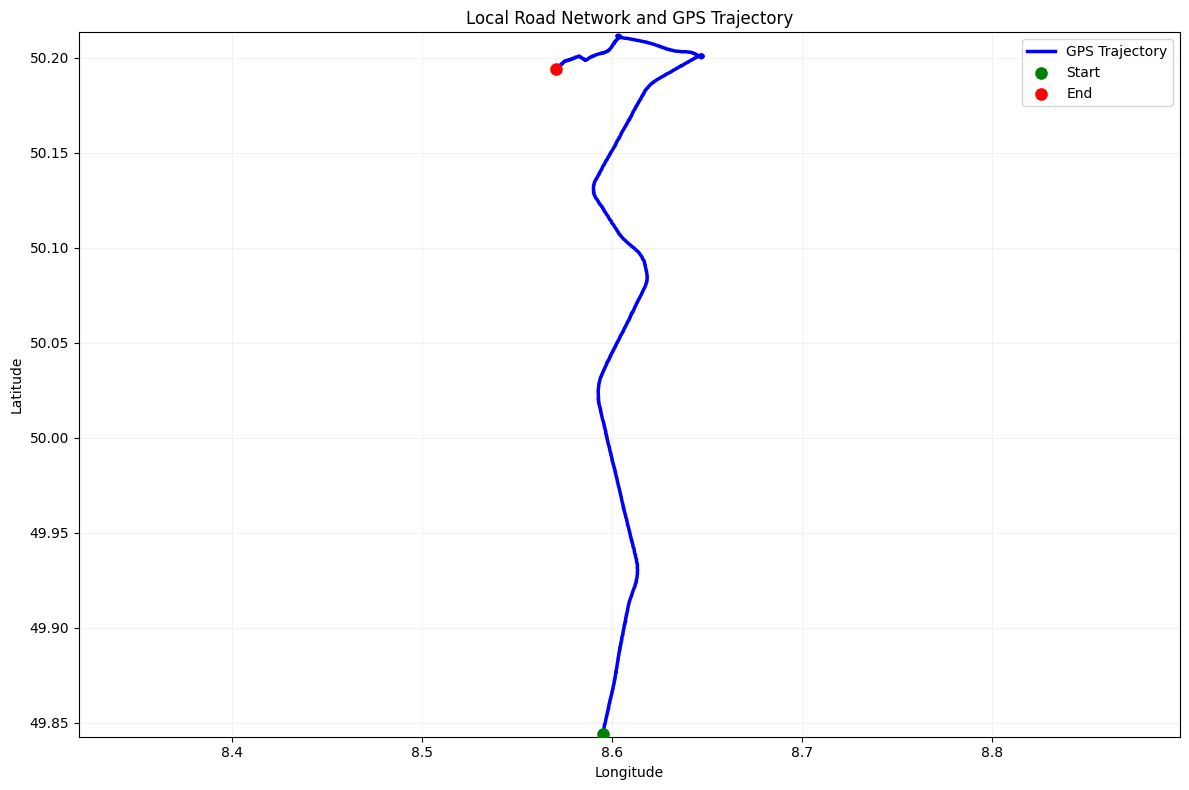

Nearby road nodes: 4039
Road segments plotted: 5283
GPS observations: 1315


In [11]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from matplotlib.collections import LineCollection

trip_id = "00000001"
folder = DATASET_DIR / trip_id

nodes = np.loadtxt(folder / f"{trip_id}.nodes", ndmin=2)
arcs = np.loadtxt(folder / f"{trip_id}.arcs", dtype=int, ndmin=2)
track = np.loadtxt(folder / f"{trip_id}.track", ndmin=2)

# GPS coordinates
gps = track[:, :2]

# Find road nodes close to GPS trajectory
tree = cKDTree(nodes)
nearby = tree.query_ball_point(gps, r=0.001)

nearby_nodes = np.unique([
    node for group in nearby for node in group
])

# Select arcs whose endpoints are both nearby
mask = np.zeros(len(nodes), dtype=bool)
mask[nearby_nodes] = True

selected_arcs = arcs[
    mask[arcs[:, 0]] & mask[arcs[:, 1]]
]

segments = np.stack([
    nodes[selected_arcs[:, 0]],
    nodes[selected_arcs[:, 1]]
], axis=1)

# Plot cleaner visualization
fig, ax = plt.subplots(figsize=(12, 8))

road_lines = LineCollection(
    segments,
    colors="grey",
    linewidths=0.45,
    alpha=0.35
)

ax.add_collection(road_lines)

ax.plot(
    gps[:, 0], gps[:, 1],
    color="blue",
    linewidth=2.5,
    label="GPS Trajectory",
    zorder=3
)

ax.scatter(
    gps[0, 0], gps[0, 1],
    color="green", s=65,
    label="Start", zorder=4
)

ax.scatter(
    gps[-1, 0], gps[-1, 1],
    color="red", s=65,
    label="End", zorder=4
)

ax.set_xlim(gps[:, 0].min() - 0.0015,
            gps[:, 0].max() + 0.0015)

ax.set_ylim(gps[:, 1].min() - 0.0015,
            gps[:, 1].max() + 0.0015)

ax.set_aspect("equal", adjustable="datalim")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Local Road Network and GPS Trajectory")
ax.legend()
ax.grid(alpha=0.15)

plt.tight_layout()
plt.show()

print("Nearby road nodes:", len(nearby_nodes))
print("Road segments plotted:", len(selected_arcs))
print("GPS observations:", len(track))

In [12]:
#Loading and validating every .track file

import numpy as np
import pandas as pd

track_data = {}
track_results = []

for folder in student_folders:

    trip_id = folder.name
    track_file = folder / f"{trip_id}.track"

    rows = []
    malformed_lines = 0
    non_numeric_values = 0

    # Read each line individually so malformed data is detected,
    # rather than silently ignored.
    with open(track_file, "r") as f:
        for line in f:

            values = line.split()

            # Each row must contain exactly 3 values
            if len(values) != 3:
                if values:
                    malformed_lines += 1
                continue

            converted = []

            for value in values:
                try:
                    converted.append(float(value))
                except ValueError:
                    converted.append(np.nan)
                    non_numeric_values += 1

            rows.append(converted)

    df = pd.DataFrame(
        rows,
        columns=["longitude", "latitude", "timestamp"]
    )

    # Check missing and infinite values
    missing_values = df.isna().sum().sum()

    infinite_values = np.isinf(
        df.to_numpy(dtype=float)
    ).sum()

    # Check coordinate validity
    invalid_lon = (
        df["longitude"].notna()
        & np.isfinite(df["longitude"])
        & ~df["longitude"].between(-180, 180)
    ).sum()

    invalid_lat = (
        df["latitude"].notna()
        & np.isfinite(df["latitude"])
        & ~df["latitude"].between(-90, 90)
    ).sum()

    # Check timestamp ordering
    valid_timestamps = df.loc[
        np.isfinite(df["timestamp"]), "timestamp"
    ]

    time_diff = valid_timestamps.diff().dropna()

    duplicate_times = (time_diff == 0).sum()
    backwards_times = (time_diff < 0).sum()

    # Identify gaps between consecutive observations
    gaps = time_diff[time_diff > 1]

    # Store this trip's DataFrame
    track_data[trip_id] = df

    # Store validation results
    track_results.append({
        "trip_id": trip_id,
        "gps_observations": len(df),
        "malformed_lines": malformed_lines,
        "non_numeric_values": non_numeric_values,
        "missing_values": missing_values,
        "infinite_values": infinite_values,
        "invalid_longitude": invalid_lon,
        "invalid_latitude": invalid_lat,
        "duplicate_timestamps": duplicate_times,
        "backwards_timestamps": backwards_times,
        "gaps_gt_1_sec": len(gaps),
        "gaps_gt_5_sec": (gaps > 5).sum(),
        "gaps_gt_10_sec": (gaps > 10).sum(),
        "longitude_min": df["longitude"].min(),
        "longitude_max": df["longitude"].max(),
        "latitude_min": df["latitude"].min(),
        "latitude_max": df["latitude"].max()
    })

track_summary = pd.DataFrame(track_results)

display(track_summary)

,trip_id,gps_observations,malformed_lines,non_numeric_values,missing_values,infinite_values,invalid_longitude,invalid_latitude,duplicate_timestamps,backwards_timestamps,gaps_gt_1_sec,gaps_gt_5_sec,gaps_gt_10_sec,longitude_min,longitude_max,latitude_min,latitude_max
0,00000001,1315,0,0,0,0,0,0,0,0,25,1,1,8.570524,8.647860,49.844053,50.211882
1,00000002,7243,0,0,0,0,0,0,0,0,184,78,41,10.999961,11.050902,47.658344,47.695459
2,00000003,821,0,0,0,0,0,0,0,0,3,0,0,37.154202,37.201595,55.977135,56.007585
3,00000004,1064,0,0,0,0,0,0,0,0,491,320,215,12.342280,12.459615,52.590308,52.718960
4,00000005,1045,0,0,0,0,0,0,0,0,0,0,0,35.485577,35.544315,49.357581,49.613085
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
75,00000095,1551,0,0,0,0,0,0,0,0,5,0,0,-1.290501,-1.268332,50.736783,50.758728
76,00000096,3271,0,0,0,0,0,0,0,0,0,0,0,-95.869374,-95.331981,36.137525,36.262757
77,00000097,1740,0,0,0,0,0,0,0,0,14,0,0,11.864978,12.220592,55.948720,56.058970
78,00000098,5584,0,0,0,0,0,0,0,0,1268,13,5,-51.669044,-51.187225,-29.701688,-29.391487


In [13]:
#Dataset summary

print("========== TRACK DATASET SUMMARY ==========")

print("Total trips:", len(track_summary))

print(
    "Total GPS observations:",
    track_summary["gps_observations"].sum()
)

print("\n========== DATA QUALITY ISSUES ==========")

quality_columns = [
    "malformed_lines",
    "non_numeric_values",
    "missing_values",
    "infinite_values",
    "invalid_longitude",
    "invalid_latitude",
    "duplicate_timestamps",
    "backwards_timestamps",
    "gaps_gt_1_sec",
    "gaps_gt_5_sec",
    "gaps_gt_10_sec"
]

display(
    track_summary[quality_columns]
    .sum()
    .to_frame("Total")
)

========== TRACK DATASET SUMMARY ==========
Total trips: 80
Total GPS observations: 208417

========== DATA QUALITY ISSUES ==========


,Total
malformed_lines,0
non_numeric_values,0
missing_values,0
infinite_values,0
invalid_longitude,0
invalid_latitude,0
duplicate_timestamps,0
backwards_timestamps,0
gaps_gt_1_sec,7286
gaps_gt_5_sec,1216


In [14]:
#inspecting individual trips with problemsd

issue_columns = [
    "malformed_lines",
    "non_numeric_values",
    "missing_values",
    "infinite_values",
    "invalid_longitude",
    "invalid_latitude",
    "duplicate_timestamps",
    "backwards_timestamps",
    "gaps_gt_1_sec"
]

trip_metrics = track_summary[
    (track_summary[issue_columns] > 0).any(axis=1)
]

print("Trips metrics:", len(trip_metrics))

display(trip_metrics)

Trips metrics: 60


,trip_id,gps_observations,malformed_lines,non_numeric_values,missing_values,infinite_values,invalid_longitude,invalid_latitude,duplicate_timestamps,backwards_timestamps,gaps_gt_1_sec,gaps_gt_5_sec,gaps_gt_10_sec,longitude_min,longitude_max,latitude_min,latitude_max
0,00000001,1315,0,0,0,0,0,0,0,0,25,1,1,8.570524,8.647860,49.844053,50.211882
1,00000002,7243,0,0,0,0,0,0,0,0,184,78,41,10.999961,11.050902,47.658344,47.695459
2,00000003,821,0,0,0,0,0,0,0,0,3,0,0,37.154202,37.201595,55.977135,56.007585
3,00000004,1064,0,0,0,0,0,0,0,0,491,320,215,12.342280,12.459615,52.590308,52.718960
5,00000006,1450,0,0,0,0,0,0,0,0,12,9,5,37.276002,37.317675,55.429164,55.487229
6,00000008,3093,0,0,0,0,0,0,0,0,1,0,0,-86.584860,-86.567487,34.733275,34.753704
8,00000011,2828,0,0,0,0,0,0,0,0,1,1,1,59.647057,60.016866,56.041788,56.067535
9,00000012,1608,0,0,0,0,0,0,0,0,1,0,0,44.044515,44.389906,36.175914,36.263587
10,00000013,2580,0,0,0,0,0,0,0,0,93,31,0,1.464353,2.137165,43.636188,43.927134
11,00000014,448,0,0,0,0,0,0,0,0,79,10,5,39.170811,39.201605,51.715319,51.733034


In [15]:
#Making csv

track_summary.to_csv(
    "track_cleaning_summary.csv",
    index=False
)

print("Track cleaning summary saved.")

Track cleaning summary saved.


In [16]:
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.neighbors import NearestNeighbors

knn_results = []

for folder in student_folders:

    trip_id = folder.name

    # Load data
    nodes = np.loadtxt(
        folder / f"{trip_id}.nodes", ndmin=2
    )

    arcs = np.loadtxt(
        folder / f"{trip_id}.arcs",
        dtype=int, ndmin=2
    )

    track = np.loadtxt(
        folder / f"{trip_id}.track", ndmin=2
    )

    # Convert coordinates approximately to local metres
    lon0 = nodes[:, 0].mean()
    lat0 = nodes[:, 1].mean()

    def to_meters(coords):
        x = (coords[:, 0] - lon0) * 111320 * np.cos(np.radians(lat0))
        y = (coords[:, 1] - lat0) * 110540
        return np.column_stack((x, y))

    road_nodes = to_meters(nodes)
    gps_points = to_meters(track[:, :2])

    # Construct road segments
    segments = road_nodes[arcs]
    midpoints = segments.mean(axis=1)

    # KNN: find 5 nearest road segment candidates
    knn = NearestNeighbors(
        n_neighbors=min(5, len(arcs)),
        algorithm="auto"
    )

    knn.fit(midpoints)

    _, candidates = knn.kneighbors(gps_points)

    predicted_arcs = []

    # Select closest actual segment among KNN candidates
    for point, candidate_ids in zip(gps_points, candidates):

        best_arc = None
        min_distance = float("inf")

        for arc_id in candidate_ids:

            a, b = segments[arc_id]

            ab = b - a
            ap = point - a

            denominator = np.dot(ab, ab)

            t = (
                np.dot(ap, ab) / denominator
                if denominator > 0 else 0
            )

            t = np.clip(t, 0, 1)

            projection = a + t * ab
            distance = np.linalg.norm(point - projection)

            if distance < min_distance:
                min_distance = distance
                best_arc = arc_id

        predicted_arcs.append(best_arc)

    # Save results
    result = pd.DataFrame({
        "trip_id": trip_id,
        "gps_observation": np.arange(len(track)),
        "predicted_arc_id": predicted_arcs
    })

    knn_results.append(result)

# Combine all trips
knn_predictions = pd.concat(knn_results, ignore_index=True)

display(knn_predictions.head(10))

print("Trips processed:", len(knn_results))
print("Total GPS observations:", len(knn_predictions))

knn_predictions.to_csv(
    "knn_map_matching_predictions.csv",
    index=False
)

,trip_id,gps_observation,predicted_arc_id
0,00000001,0,64973
1,00000001,1,64973
2,00000001,2,64973
3,00000001,3,64973
4,00000001,4,64973
5,00000001,5,64973
6,00000001,6,133948
7,00000001,7,133949
8,00000001,8,139208
9,00000001,9,139208


Trips processed: 80
Total GPS observations: 208417


In [17]:
#Reconstructing route from nodes and arcs

import numpy as np
import pandas as pd

trip_id = "00000001"
folder = DATASET_DIR / trip_id

# Load trip data
nodes = np.loadtxt(
    folder / f"{trip_id}.nodes",
    ndmin=2
)

arcs = np.loadtxt(
    folder / f"{trip_id}.arcs",
    dtype=int,
    ndmin=2
)

track = np.loadtxt(
    folder / f"{trip_id}.track",
    ndmin=2
)

route_ids = np.loadtxt(
    folder / f"{trip_id}.route",
    dtype=int,
    ndmin=1
).ravel()

# Reconstruct the reference route
route_arcs = arcs[route_ids]

# Obtain the coordinates of each route segment
route_start = nodes[route_arcs[:, 0], :2]
route_end = nodes[route_arcs[:, 1], :2]

gps = track[:, :2]

print("GPS observations:", len(gps))
print("Reference route segments:", len(route_arcs))
print("Road nodes:", len(nodes))

print("\nFirst 5 reconstructed route segments:")
print(route_start[:5])
print(route_end[:5])

GPS observations: 1315
Reference route segments: 525
Road nodes: 88809

First 5 reconstructed route segments:
[[ 8.594417 49.839972]
 [ 8.595156 49.843765]
 [ 8.595675 49.846381]
 [ 8.595725 49.846644]
 [ 8.595827 49.847161]]
[[ 8.595156 49.843765]
 [ 8.595675 49.846381]
 [ 8.595725 49.846644]
 [ 8.595827 49.847161]
 [ 8.59594  49.847732]]


In [18]:
# Convert longitude/latitude into approximate local metre coordinates

R = 6371000

reference_lat = np.radians(
    np.mean(gps[:, 1])
)

def to_metres(coords):
    lon = np.radians(coords[:, 0])
    lat = np.radians(coords[:, 1])

    x = R * lon * np.cos(reference_lat)
    y = R * lat

    return np.column_stack((x, y))


gps_m = to_metres(gps)
start_m = to_metres(route_start)
end_m = to_metres(route_end)

# Vector along each road segment
vectors = end_m - start_m

length_squared = np.sum(
    vectors ** 2,
    axis=1
)

# Avoid division by zero for zero-length segments
length_squared = np.maximum(length_squared, 1e-12)

# Difference between each GPS point and each segment's start
difference = (
    gps_m[:, None, :] - start_m[None, :, :]
)

# Project GPS points onto road segments
t = np.sum(
    difference * vectors[None, :, :],
    axis=2
) / length_squared[None, :]

# Keep projections within the segment
t = np.clip(t, 0, 1)

# Calculate closest points on each segment
closest_points = (
    start_m[None, :, :]
    + t[:, :, None] * vectors[None, :, :]
)

# Calculate distances in metres
distances = np.linalg.norm(
    gps_m[:, None, :] - closest_points,
    axis=2
)

print("Distance matrix shape:", distances.shape)
print("Rows = GPS observations")
print("Columns = reference route segments")

Distance matrix shape: (1315, 525)
Rows = GPS observations
Columns = reference route segments


In [19]:
# Find the closest reference-route segment
best_positions = np.argmin(distances, axis=1)

best_distances = distances[
    np.arange(len(gps)),
    best_positions
]

# Map route positions back to original arc IDs
predicted_arc_ids = route_ids[best_positions]

# Create labelled dataset
labels_df = pd.DataFrame({
    "trip_id": trip_id,
    "gps_index": np.arange(len(gps)),
    "longitude": gps[:, 0],
    "latitude": gps[:, 1],
    "timestamp": track[:, 2],
    "route_position": best_positions,
    "arc_id": predicted_arc_ids,
    "distance_to_road_m": best_distances
})

display(labels_df.head(15))

print("\nUnique road arc labels:", labels_df["arc_id"].nunique())
print("Mean matching distance:", labels_df["distance_to_road_m"].mean())
print("Maximum matching distance:", labels_df["distance_to_road_m"].max())
print("\nDistance percentiles:")
print(labels_df["distance_to_road_m"].describe(
    percentiles=[0.5, 0.75, 0.90, 0.95, 0.99]
))

,trip_id,gps_index,longitude,latitude,timestamp,route_position,arc_id,distance_to_road_m
0,00000001,0,8.595203,49.844053,1.0,1,64973,0.717461
1,00000001,1,8.595294,49.844441,2.0,1,64973,0.274973
2,00000001,2,8.595352,49.844883,3.0,1,64973,1.826280
3,00000001,3,8.595390,49.845379,4.0,1,64973,6.101181
4,00000001,4,8.595587,49.845750,5.0,1,64973,2.631801
5,00000001,5,8.595555,49.846167,6.0,1,64973,5.487930
6,00000001,6,8.595744,49.846565,7.0,2,133948,2.409171
7,00000001,7,8.595733,49.846931,8.0,3,133949,3.441449
8,00000001,8,8.595878,49.847374,9.0,4,139208,0.626192
9,00000001,9,8.595849,49.847684,10.0,4,139208,5.768226



Unique road arc labels: 458
Mean matching distance: 5.002535520966825
Maximum matching distance: 27.210604823913744

Distance percentiles:
count    1315.000000
mean        5.002536
std         3.774982
min         0.004126
50%         4.289783
75%         7.175178
90%        10.157846
95%        12.355551
99%        15.679178
max        27.210605
Name: distance_to_road_m, dtype: float64


In [20]:

import numpy as np
import pandas as pd
from pathlib import Path

# Output directory
OUTPUT_DIR = BASE_DIR / "pathsnap_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Matching parameters
TOP_K = 12
GPS_SIGMA = 10.0       # Expected GPS error in metres
TRANSITION_SIGMA = 25.0  # Tolerance for movement between observations

R = 6371000


def to_metres(coords, reference_lat):
    lon = np.radians(coords[:, 0])
    lat = np.radians(coords[:, 1])

    x = R * lon * np.cos(reference_lat)
    y = R * lat

    return np.column_stack((x, y))


def generate_trip_labels(folder):

    trip_id = folder.name

    nodes = np.loadtxt(
        folder / f"{trip_id}.nodes", ndmin=2
    )

    arcs = np.loadtxt(
        folder / f"{trip_id}.arcs",
        dtype=int, ndmin=2
    )

    track = np.loadtxt(
        folder / f"{trip_id}.track", ndmin=2
    )

    route_ids = np.loadtxt(
        folder / f"{trip_id}.route",
        dtype=int, ndmin=1
    ).ravel()

    # Validate route IDs
    if len(route_ids) == 0:
        raise ValueError("Empty route")

    if np.any(route_ids < 0) or np.any(route_ids >= len(arcs)):
        raise ValueError("Invalid arc ID in route")

    # Reconstruct reference route
    route_arcs = arcs[route_ids]

    route_start = nodes[route_arcs[:, 0], :2]
    route_end = nodes[route_arcs[:, 1], :2]

    gps = track[:, :2]

    reference_lat = np.radians(np.mean(gps[:, 1]))

    gps_m = to_metres(gps, reference_lat)
    start_m = to_metres(route_start, reference_lat)
    end_m = to_metres(route_end, reference_lat)

    # Calculate distance from every GPS point to every route segment
    vectors = end_m - start_m

    lengths = np.linalg.norm(vectors, axis=1)
    length_squared = np.maximum(lengths ** 2, 1e-12)

    difference = gps_m[:, None, :] - start_m[None, :, :]

    projection = np.sum(
        difference * vectors[None, :, :], axis=2
    ) / length_squared[None, :]

    projection = np.clip(projection, 0, 1)

    closest_points = (
        start_m[None, :, :]
        + projection[:, :, None] * vectors[None, :, :]
    )

    distances = np.linalg.norm(
        gps_m[:, None, :] - closest_points,
        axis=2
    )

    # Keep the 12 closest route segments for each GPS point
    k = min(TOP_K, len(route_ids))

    candidates = np.argpartition(
        distances, k - 1, axis=1
    )[:, :k]

    candidates.sort(axis=1)

    candidate_distances = np.take_along_axis(
        distances, candidates, axis=1
    )

    # Calculate distance travelled along the reference route
    cumulative_lengths = np.concatenate([
        [0],
        np.cumsum(lengths)
    ])

    route_progress = (
        cumulative_lengths[:-1][None, :]
        + projection * lengths[None, :]
    )

    candidate_progress = np.take_along_axis(
        route_progress, candidates, axis=1
    )

    # Emission cost: how far is the GPS point from the road?
    emission_cost = (
        candidate_distances ** 2
        / (2 * GPS_SIGMA ** 2)
    )

    n = len(gps)

    dp = np.full((n, k), np.inf)
    backtrack = np.full((n, k), -1, dtype=int)

    dp[0] = emission_cost[0]

    # Dynamic programming: enforce forward route progression
    for t in range(1, n):

        gps_movement = np.linalg.norm(
            gps_m[t] - gps_m[t - 1]
        )

        previous = candidate_progress[t - 1]
        current = candidate_progress[t]

        movement = current[None, :] - previous[:, None]

        valid = movement >= -1e-6

        transition_cost = (
            (movement - gps_movement) ** 2
            / (2 * TRANSITION_SIGMA ** 2)
        )

        transition_cost[~valid] = np.inf

        total_cost = (
            dp[t - 1][:, None]
            + transition_cost
        )

        best_previous = np.argmin(total_cost, axis=0)

        dp[t] = (
            total_cost[best_previous, np.arange(k)]
            + emission_cost[t]
        )

        backtrack[t] = best_previous

    # Recover the best complete route-position sequence
    states = np.zeros(n, dtype=int)
    states[-1] = np.argmin(dp[-1])

    for t in range(n - 1, 0, -1):
        states[t - 1] = backtrack[t, states[t]]

    selected_positions = candidates[
        np.arange(n), states
    ]

    selected_distances = distances[
        np.arange(n), selected_positions
    ]

    selected_arc_ids = route_ids[selected_positions]

    # Build output labels
    labels = pd.DataFrame({
        "trip_id": trip_id,
        "gps_index": np.arange(n),
        "longitude": gps[:, 0],
        "latitude": gps[:, 1],
        "timestamp": track[:, 2],
        "route_position": selected_positions,
        "arc_id": selected_arc_ids,
        "distance_to_road_m": selected_distances
    })

    # Attach a simple quality indicator
    labels["label_quality"] = np.select(
        [
            labels["distance_to_road_m"] <= 10,
            labels["distance_to_road_m"] <= 20
        ],
        [
            "high",
            "medium"
        ],
        default="low"
    )

    return labels


# Process every training trip
all_labels = []
failed_trips = []

for folder in student_folders:

    try:
        labels = generate_trip_labels(folder)
        all_labels.append(labels)

        print(
            f"{folder.name}: "
            f"{len(labels)} GPS points labelled"
        )

    except Exception as e:
        failed_trips.append({
            "trip_id": folder.name,
            "error": str(e)
        })

# Combine all successful trips
if all_labels:
    virtual_labels = pd.concat(
        all_labels,
        ignore_index=True
    )

    virtual_labels.to_csv(
        OUTPUT_DIR / "virtual_labels.csv",
        index=False
    )

    print("\n========== LABEL GENERATION SUMMARY ==========")
    print("Trips labelled:", len(all_labels))
    print("GPS observations labelled:", len(virtual_labels))

    print("\nLabel quality:")
    print(virtual_labels["label_quality"].value_counts())

    print("\nDistance statistics:")
    print(
        virtual_labels["distance_to_road_m"].describe(
            percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
        )
    )

if failed_trips:
    print("\nFailed trips:")
    display(pd.DataFrame(failed_trips))

print("\nSaved to:", OUTPUT_DIR / "virtual_labels.csv")


00000001: 1315 GPS points labelled
00000002: 7243 GPS points labelled
00000003: 821 GPS points labelled
00000004: 1064 GPS points labelled
00000005: 1045 GPS points labelled
00000006: 1450 GPS points labelled
00000008: 3093 GPS points labelled
00000010: 2711 GPS points labelled
00000011: 2828 GPS points labelled
00000012: 1608 GPS points labelled
00000013: 2580 GPS points labelled
00000014: 448 GPS points labelled
00000016: 1305 GPS points labelled
00000018: 379 GPS points labelled
00000019: 2354 GPS points labelled
00000020: 2353 GPS points labelled
00000021: 15783 GPS points labelled
00000022: 474 GPS points labelled
00000024: 801 GPS points labelled
00000025: 1179 GPS points labelled
00000026: 361 GPS points labelled
00000027: 694 GPS points labelled
00000028: 3565 GPS points labelled
00000029: 733 GPS points labelled
00000031: 4245 GPS points labelled
00000032: 2464 GPS points labelled
00000033: 5844 GPS points labelled
00000034: 3614 GPS points labelled
00000035: 1643 GPS points l

## Model Training and Evaluation

The generated virtual labels are derived from the supplied route files using route-projection and dynamic programming.

The five ML classifiers use the same high-confidence labels, candidate-road generation, extracted features and trip-grouped cross-validation.

Student-test evaluation uses route-derived reference labels. These are not independently annotated GPS ground-truth labels.

In [ ]:

# ============================================================
# SHARED CANDIDATE PREPROCESSING FOR ALL FOUR ML CLASSIFIERS
# Uses the same high-confidence labels and candidate features
# for KNN, Random Forest, XGBoost and LightGBM, Logistic Regression .
# ============================================================

import numpy as np
import pandas as pd
import time
import joblib
from pathlib import Path
from scipy.spatial import cKDTree
from sklearn.model_selection import GroupKFold, train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_auc_score, log_loss
)

OUTPUT_DIR = BASE_DIR / "pathsnap_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

LABELS_PATH = OUTPUT_DIR / "virtual_labels.csv"
TOP_K = 12
SEARCH_K = 30
MAX_LABEL_DISTANCE = 10.0
CHUNK_SIZE = 256
CV_FOLDS = 3
RANDOM_STATE = 42

EARTH_RADIUS = 6371000.0

def to_metres_shared(coords, reference_lat):
    coords = np.asarray(coords)
    lon = np.radians(coords[:, 0])
    lat = np.radians(coords[:, 1])
    x = EARTH_RADIUS * lon * np.cos(reference_lat)
    y = EARTH_RADIUS * lat
    return np.column_stack((x, y))

def angle_difference_shared(a, b):
    return np.abs((a - b + np.pi) % (2 * np.pi) - np.pi)

print("Loading high-confidence virtual labels...")
virtual_labels = pd.read_csv(
    LABELS_PATH,
    dtype={"trip_id": str}
)
virtual_labels["trip_id"] = (
    virtual_labels["trip_id"].astype(str).str.zfill(8)
)
virtual_labels["gps_index"] = virtual_labels["gps_index"].astype(int)
virtual_labels["arc_id"] = virtual_labels["arc_id"].astype(int)

virtual_labels = virtual_labels[
    virtual_labels["distance_to_road_m"] <= MAX_LABEL_DISTANCE
].copy()

print("High-confidence labels:", len(virtual_labels))
print("Trips represented:", virtual_labels["trip_id"].nunique())

# One row per candidate road segment for each labelled GPS observation.
candidate_parts = []
total_labelled_points = 0
covered_labelled_points = 0
failed_candidate_trips = []

for folder in student_folders:
    trip_id = folder.name
    trip_labels = virtual_labels[
        virtual_labels["trip_id"] == trip_id
    ].sort_values("gps_index").copy()

    if trip_labels.empty:
        continue

    try:
        nodes = np.loadtxt(
            folder / f"{trip_id}.nodes", ndmin=2
        )
        arcs = np.loadtxt(
            folder / f"{trip_id}.arcs", dtype=int, ndmin=2
        )
        track = np.loadtxt(
            folder / f"{trip_id}.track", ndmin=2
        )

        gps = track[:, :2]
        timestamps = track[:, 2]

        valid_arc_mask = (
            (arcs[:, 0] >= 0) & (arcs[:, 1] >= 0) &
            (arcs[:, 0] < len(nodes)) &
            (arcs[:, 1] < len(nodes))
        )
        original_arc_ids = np.flatnonzero(valid_arc_mask)
        valid_arcs = arcs[valid_arc_mask]

        if len(valid_arcs) == 0:
            continue

        trip_labels = trip_labels[
            trip_labels["gps_index"].between(0, len(gps) - 1)
        ]

        if trip_labels.empty:
            continue

        gps_indices = trip_labels["gps_index"].to_numpy()
        target_arc_ids = trip_labels["arc_id"].to_numpy()

        reference_lat = np.radians(np.mean(gps[:, 1]))
        gps_m = to_metres_shared(gps, reference_lat)

        starts = to_metres_shared(
            nodes[valid_arcs[:, 0], :2], reference_lat
        )
        ends = to_metres_shared(
            nodes[valid_arcs[:, 1], :2], reference_lat
        )
        vectors = ends - starts
        lengths = np.linalg.norm(vectors, axis=1)
        length_sq = np.maximum(np.sum(vectors * vectors, axis=1), 1e-12)
        bearings = np.arctan2(vectors[:, 0], vectors[:, 1])
        midpoints = (starts + ends) / 2

        # GPS movement features
        gps_delta = np.zeros_like(gps_m)
        gps_delta[1:] = gps_m[1:] - gps_m[:-1]
        time_delta = np.zeros(len(gps))
        time_delta[1:] = np.diff(timestamps)
        gps_speed = np.zeros(len(gps))
        valid_time = time_delta > 0
        gps_speed[valid_time] = (
            np.linalg.norm(gps_delta[valid_time], axis=1)
            / time_delta[valid_time]
        )
        gps_bearing = np.arctan2(gps_delta[:, 0], gps_delta[:, 1])

        tree = cKDTree(midpoints)
        k_search = min(SEARCH_K, len(valid_arcs))
        k_candidates = min(TOP_K, len(valid_arcs))

        for batch_start in range(0, len(gps_indices), CHUNK_SIZE):
            batch_idx = gps_indices[batch_start:batch_start + CHUNK_SIZE]
            batch_target = target_arc_ids[batch_start:batch_start + CHUNK_SIZE]
            batch_gps = gps_m[batch_idx]

            _, nearby_pos = tree.query(batch_gps, k=k_search)
            nearby_pos = np.asarray(nearby_pos).reshape(len(batch_idx), k_search)

            a = starts[nearby_pos]
            v = vectors[nearby_pos]
            denom = np.maximum(np.sum(v * v, axis=2), 1e-12)
            proj = np.sum((batch_gps[:, None, :] - a) * v, axis=2) / denom
            proj = np.clip(proj, 0, 1)
            closest = a + proj[:, :, None] * v
            dists = np.linalg.norm(batch_gps[:, None, :] - closest, axis=2)

            # Rank nearby midpoint candidates by actual point-to-segment distance.
            chosen = np.argsort(dists, axis=1)[:, :k_candidates]
            pos = np.take_along_axis(nearby_pos, chosen, axis=1)
            cand_dist = np.take_along_axis(dists, chosen, axis=1)
            cand_proj = np.take_along_axis(proj, chosen, axis=1)

            cand_arc_ids = original_arc_ids[pos]
            cand_lengths = lengths[pos]
            cand_bearings = bearings[pos]

            positive = cand_arc_ids == batch_target[:, None]
            covered = positive.any(axis=1)
            total_labelled_points += len(batch_idx)
            covered_labelled_points += int(covered.sum())

            if not covered.any():
                continue

            # Retain all K candidates for observations whose true label is present.
            rows = np.where(covered)[0]
            flat_pos = pos[rows]
            flat_idx = batch_idx[rows]
            flat_target = batch_target[rows]
            flat_dist = cand_dist[rows]
            flat_proj = cand_proj[rows]
            flat_lengths = cand_lengths[rows]
            flat_bearings = cand_bearings[rows]
            flat_positive = positive[rows]

            repeated_gps_bearing = np.repeat(gps_bearing[flat_idx, None], k_candidates, axis=1)
            heading_diff = angle_difference_shared(
                repeated_gps_bearing, flat_bearings
            )

            part = pd.DataFrame({
                "distance_to_segment": flat_dist.ravel(),
                "segment_length": flat_lengths.ravel(),
                "projection_position": flat_proj.ravel(),
                "gps_speed": np.repeat(gps_speed[flat_idx], k_candidates),
                "time_delta": np.repeat(time_delta[flat_idx], k_candidates),
                "gps_bearing": repeated_gps_bearing.ravel(),
                "segment_bearing": flat_bearings.ravel(),
                "heading_difference": heading_diff.ravel(),
                "on_route": flat_positive.astype("int8").ravel(),
                "trip_id": np.repeat(trip_id, len(rows) * k_candidates),
                "gps_index": np.repeat(flat_idx, k_candidates),
                "candidate_arc_index": original_arc_ids[flat_pos].ravel(),
                "from_node": valid_arcs[flat_pos, 0].ravel(),
                "to_node": valid_arcs[flat_pos, 1].ravel()
            })
            candidate_parts.append(part)

        print(f"{trip_id}: processed {len(trip_labels)} labelled observations")

    except Exception as exc:
        failed_candidate_trips.append((trip_id, str(exc)))
        print(f"{trip_id}: FAILED - {exc}")

if not candidate_parts:
    raise ValueError("No candidate rows generated. Check labels and trip folders.")

candidate_df = pd.concat(candidate_parts, ignore_index=True)

feature_columns = [
    "distance_to_segment",
    "segment_length",
    "projection_position",
    "gps_speed",
    "time_delta",
    "gps_bearing",
    "segment_bearing",
    "heading_difference"
]

X = candidate_df[feature_columns].replace(
    [np.inf, -np.inf], np.nan
).fillna(0).astype("float32")

y = candidate_df["on_route"].astype("int8")
groups = candidate_df["trip_id"].astype(str)

print("\n========== SHARED CANDIDATE DATASET ==========")
print("Candidate rows:", len(candidate_df))
print("High-confidence observations:", total_labelled_points)
print("Observations with true arc in candidate set:", covered_labelled_points)
print(
    "Candidate coverage:",
    f"{covered_labelled_points / max(total_labelled_points, 1):.2%}"
)
print("Positive candidate rows:", int(y.sum()))
print("Negative candidate rows:", int((y == 0).sum()))
print("Trips represented:", groups.nunique())
print("Trips with preprocessing errors:", failed_candidate_trips)

def sample_training_indices(indices, labels, max_rows):
    indices = np.asarray(indices)
    if len(indices) <= max_rows:
        return indices
    sampled, _ = train_test_split(
        indices,
        train_size=max_rows,
        stratify=labels.iloc[indices],
        random_state=RANDOM_STATE
    )
    return np.asarray(sampled)

def run_candidate_model(model_name, model_factory, max_train_rows, model_filename):
    """Trip-grouped 3-fold out-of-fold evaluation, then fit final model."""
    oof_probability = np.full(len(candidate_df), np.nan, dtype=float)
    fold_train_time = 0.0
    fold_inference_time = 0.0

    splitter = GroupKFold(n_splits=CV_FOLDS)

    for fold, (train_idx, valid_idx) in enumerate(
        splitter.split(X, y, groups=groups), start=1
    ):
        sampled_idx = sample_training_indices(
            train_idx, y, max_train_rows
        )
        fold_model = model_factory()

        start_time = time.perf_counter()
        fold_model.fit(X.iloc[sampled_idx], y.iloc[sampled_idx])
        fold_train_time += time.perf_counter() - start_time

        start_time = time.perf_counter()
        fold_prob = []
        # Chunk inference to avoid large temporary memory use.
        for begin in range(0, len(valid_idx), 100000):
            ids = valid_idx[begin:begin + 100000]
            fold_prob.extend(
                fold_model.predict_proba(X.iloc[ids])[:, 1]
            )
        fold_inference_time += time.perf_counter() - start_time

        oof_probability[valid_idx] = np.asarray(fold_prob)
        print(f"{model_name}: fold {fold}/{CV_FOLDS} complete")

    valid_mask = np.isfinite(oof_probability)
    y_true = y.to_numpy()[valid_mask]
    prob = oof_probability[valid_mask]
    predicted_class = (prob >= 0.5).astype(int)

    candidate_accuracy = accuracy_score(y_true, predicted_class)
    precision = precision_score(y_true, predicted_class, zero_division=0)
    recall = recall_score(y_true, predicted_class, zero_division=0)
    f1 = f1_score(y_true, predicted_class, zero_division=0)
    auc = (
        roc_auc_score(y_true, prob)
        if len(np.unique(y_true)) == 2 else np.nan
    )
    loss = log_loss(y_true, prob, labels=[0, 1])

    oof = candidate_df.loc[valid_mask].copy()
    oof["probability"] = prob
    best = oof.loc[
        oof.groupby(["trip_id", "gps_index"])["probability"].idxmax()
    ].copy()
    top1 = float(best["on_route"].mean())

    # Check whether consecutive predicted directed arcs connect.
    continuity_checks = []
    for _, trip_group in best.groupby("trip_id"):
        trip_group = trip_group.sort_values("gps_index")
        idx = trip_group["gps_index"].to_numpy()
        from_nodes = trip_group["from_node"].to_numpy()
        to_nodes = trip_group["to_node"].to_numpy()
        consecutive = np.diff(idx) == 1
        if consecutive.any():
            connected = to_nodes[:-1] == from_nodes[1:]
            continuity_checks.extend(connected[consecutive].tolist())
    continuity = (
        float(np.mean(continuity_checks))
        if continuity_checks else np.nan
    )

    print(f"\n========== {model_name.upper()} EVALUATION ==========")
    print("Candidate accuracy:", round(candidate_accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1-score:", round(f1, 4))
    print("ROC-AUC:", round(auc, 4) if np.isfinite(auc) else "N/A")
    print("Log loss:", round(loss, 4))
    print("Confusion matrix:\n", confusion_matrix(y_true, predicted_class))
    print("Observation Top-1 accuracy:", round(top1, 4))
    print("Route continuity:", round(continuity, 4))
    print("CV training time (s):", round(fold_train_time, 2))
    print("CV inference time (s):", round(fold_inference_time, 2))

    # Fit final deployable model using all available trips.
    final_indices = sample_training_indices(
        np.arange(len(X)), y, max_train_rows
    )
    final_model = model_factory()
    final_start = time.perf_counter()
    final_model.fit(X.iloc[final_indices], y.iloc[final_indices])
    final_fit_time = time.perf_counter() - final_start

    model_path = OUTPUT_DIR / model_filename
    joblib.dump(final_model, model_path)

    best_path = OUTPUT_DIR / f"{model_name.lower().replace(' ', '_')}_oof_predictions.csv"
    best.to_csv(best_path, index=False)

    result = {
        "model": model_name,
        "candidate_accuracy": candidate_accuracy,
        "precision": precision,
        "recall": recall,
        "f1_score": f1,
        "roc_auc": auc,
        "log_loss": loss,
        "top1_accuracy": top1,
        "route_continuity": continuity,
        "cv_training_time_seconds": fold_train_time,
        "cv_inference_time_seconds": fold_inference_time,
        "final_fit_time_seconds": final_fit_time,
        "candidate_coverage": covered_labelled_points / max(total_labelled_points, 1)
    }

    pd.DataFrame([result]).to_csv(
        OUTPUT_DIR / f"{model_name.lower().replace(' ', '_')}_metrics.csv",
        index=False
    )
    print("Saved model:", model_path)
    print("Saved top-1 predictions:", best_path)
    return final_model, result

model_results = []


Loading high-confidence virtual labels...
High-confidence labels: 105565
Trips represented: 80
00000001: processed 1178 labelled observations
00000002: processed 2514 labelled observations
00000003: processed 438 labelled observations
00000004: processed 485 labelled observations
00000005: processed 903 labelled observations
00000006: processed 1082 labelled observations
00000008: processed 454 labelled observations
00000010: processed 1121 labelled observations
00000011: processed 2228 labelled observations
00000012: processed 1244 labelled observations
00000013: processed 2165 labelled observations
00000014: processed 352 labelled observations
00000016: processed 561 labelled observations
00000018: processed 339 labelled observations
00000019: processed 1597 labelled observations
00000020: processed 1555 labelled observations
00000021: processed 2522 labelled observations
00000022: processed 382 labelled observations
00000024: processed 720 labelled observations
00000025: processed 9

### Model 1 — K-Nearest Neighbors (KNN)

In [22]:

# ============================================================
# MODEL 1: K-NEAREST NEIGHBORS (KNN)
# ============================================================

from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

knn_model, knn_metrics = run_candidate_model(
    model_name="KNN",
    model_factory=lambda: make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(
            n_neighbors=7,
            weights="distance",
            metric="minkowski",
            n_jobs=-1
        )
    ),
    max_train_rows=80000,
    model_filename="knn_map_matching_model.joblib"
)

model_results.append(knn_metrics)


KNN: fold 1/3 complete
KNN: fold 2/3 complete
KNN: fold 3/3 complete

========== KNN EVALUATION ==========
Candidate accuracy: 0.9532
Precision: 0.7681
Recall: 0.6271
F1-score: 0.6905
ROC-AUC: 0.9223
Log loss: 0.4619
Confusion matrix:
 [[1114256   19514]
 [  38431   64639]]
Observation Top-1 accuracy: 0.7363
Route continuity: 0.2062
CV training time (s): 0.27
CV inference time (s): 48.13
Saved model: c:\Users\PAVAN KUMAR K M\OneDrive\Documents\Student folder\pathsnap_outputs\knn_map_matching_model.joblib
Saved top-1 predictions: c:\Users\PAVAN KUMAR K M\OneDrive\Documents\Student folder\pathsnap_outputs\knn_oof_predictions.csv


### Model 2 — Random Forest

In [23]:

# ============================================================
# MODEL 2: RANDOM FOREST
# ============================================================

from sklearn.ensemble import RandomForestClassifier

rf_model, rf_metrics = run_candidate_model(
    model_name="Random Forest",
    model_factory=lambda: RandomForestClassifier(
        n_estimators=200,
        max_depth=20,
        min_samples_split=5,
        min_samples_leaf=2,
        max_features="sqrt",
        class_weight="balanced_subsample",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    max_train_rows=400000,
    model_filename="random_forest_map_matching_model.joblib"
)

model_results.append(rf_metrics)

# Feature importance from the final Random Forest.
rf_importance = pd.DataFrame({
    "feature": feature_columns,
    "importance": rf_model.feature_importances_
}).sort_values("importance", ascending=False)

display(rf_importance)
rf_importance.to_csv(
    OUTPUT_DIR / "random_forest_feature_importance.csv",
    index=False
)


Random Forest: fold 1/3 complete
Random Forest: fold 2/3 complete
Random Forest: fold 3/3 complete

========== RANDOM FOREST EVALUATION ==========
Candidate accuracy: 0.9667
Precision: 0.7627
Recall: 0.8717
F1-score: 0.8136
ROC-AUC: 0.9903
Log loss: 0.0768
Confusion matrix:
 [[1105822   27948]
 [  13221   89849]]
Observation Top-1 accuracy: 0.8442
Route continuity: 0.2349
CV training time (s): 36.94
CV inference time (s): 1.58
Saved model: c:\Users\PAVAN KUMAR K M\OneDrive\Documents\Student folder\pathsnap_outputs\random_forest_map_matching_model.joblib
Saved top-1 predictions: c:\Users\PAVAN KUMAR K M\OneDrive\Documents\Student folder\pathsnap_outputs\random_forest_oof_predictions.csv


,feature,importance
0,distance_to_segment,0.547292
7,heading_difference,0.200802
2,projection_position,0.143497
3,gps_speed,0.035403
1,segment_length,0.033497
6,segment_bearing,0.020252
5,gps_bearing,0.017958
4,time_delta,0.001300


In [27]:
%pip install xgboost lightgbm

  Using cached xgboost-3.4.1-py3-none-win_amd64.whl.metadata (2.0 kB)
  Using cached lightgbm-4.7.0-py3-none-win_amd64.whl.metadata (18 kB)
Using cached xgboost-3.4.1-py3-none-win_amd64.whl (48.9 MB)
Using cached lightgbm-4.7.0-py3-none-win_amd64.whl (1.4 MB)

   ---------------------------------------- 0/2 [xgboost]
   ---------------------------------------- 0/2 [xgboost]
   ---------------------------------------- 0/2 [xgboost]
   ---------------------------------------- 0/2 [xgboost]
   ---------------------------------------- 0/2 [xgboost]
   ---------------------------------------- 0/2 [xgboost]
   -------------------- ------------------- 1/2 [lightgbm]
   -------------------- ------------------- 1/2 [lightgbm]
   ---------------------------------------- 2/2 [lightgbm]

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


### Model 3 — XGBoost

In [28]:

# ============================================================
# MODEL 3: XGBOOST
# ============================================================

# If needed in a fresh Colab runtime, run:
# %pip -q install xgboost

from xgboost import XGBClassifier

negative_count = int((y == 0).sum())
positive_count = int((y == 1).sum())
scale_pos_weight = negative_count / max(positive_count, 1)

xgb_model, xgb_metrics = run_candidate_model(
    model_name="XGBoost",
    model_factory=lambda: XGBClassifier(
        n_estimators=400,
        max_depth=7,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        min_child_weight=3,
        scale_pos_weight=scale_pos_weight,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    max_train_rows=500000,
    model_filename="xgboost_map_matching_model.joblib"
)

model_results.append(xgb_metrics)

xgb_importance = pd.DataFrame({
    "feature": feature_columns,
    "importance": xgb_model.feature_importances_
}).sort_values("importance", ascending=False)

display(xgb_importance)
xgb_importance.to_csv(
    OUTPUT_DIR / "xgboost_feature_importance.csv",
    index=False
)


XGBoost: fold 1/3 complete
XGBoost: fold 2/3 complete
XGBoost: fold 3/3 complete

========== XGBOOST EVALUATION ==========
Candidate accuracy: 0.9458
Precision: 0.6125
Recall: 0.952
F1-score: 0.7454
ROC-AUC: 0.9906
Log loss: 0.111
Confusion matrix:
 [[1071699   62071]
 [   4945   98125]]
Observation Top-1 accuracy: 0.8434
Route continuity: 0.2333
CV training time (s): 13.94
CV inference time (s): 1.1
Saved model: c:\Users\PAVAN KUMAR K M\OneDrive\Documents\Student folder\pathsnap_outputs\xgboost_map_matching_model.joblib
Saved top-1 predictions: c:\Users\PAVAN KUMAR K M\OneDrive\Documents\Student folder\pathsnap_outputs\xgboost_oof_predictions.csv


,feature,importance
0,distance_to_segment,0.715627
2,projection_position,0.109225
7,heading_difference,0.104786
3,gps_speed,0.026379
1,segment_length,0.012926
5,gps_bearing,0.010596
6,segment_bearing,0.010379
4,time_delta,0.010081


### Model 4 — LightGBM

If LightGBM is not installed in the Colab runtime, uncomment and run `%pip -q install lightgbm` in this cell, then rerun the cell.

In [29]:

# ============================================================
# MODEL 4: LIGHTGBM
# ============================================================

# Install once in Colab if LightGBM is not available:
# %pip -q install lightgbm

import lightgbm as lgb

lgb_model, lgb_metrics = run_candidate_model(
    model_name="LightGBM",
    model_factory=lambda: lgb.LGBMClassifier(
        objective="binary",
        n_estimators=400,
        learning_rate=0.05,
        num_leaves=31,
        min_child_samples=40,
        reg_lambda=1.0,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbosity=-1
    ),
    max_train_rows=500000,
    model_filename="lightgbm_map_matching_model.joblib"
)

model_results.append(lgb_metrics)

lgb_importance = pd.DataFrame({
    "feature": feature_columns,
    "importance": lgb_model.feature_importances_
}).sort_values("importance", ascending=False)

display(lgb_importance)
lgb_importance.to_csv(
    OUTPUT_DIR / "lightgbm_feature_importance.csv",
    index=False
)


LightGBM: fold 1/3 complete
LightGBM: fold 2/3 complete
LightGBM: fold 3/3 complete

========== LIGHTGBM EVALUATION ==========
Candidate accuracy: 0.9414
Precision: 0.5914
Recall: 0.9613
F1-score: 0.7323
ROC-AUC: 0.9907
Log loss: 0.1171
Confusion matrix:
 [[1065304   68466]
 [   3984   99086]]
Observation Top-1 accuracy: 0.8438
Route continuity: 0.235
CV training time (s): 6.15
CV inference time (s): 1.52
Saved model: c:\Users\PAVAN KUMAR K M\OneDrive\Documents\Student folder\pathsnap_outputs\lightgbm_map_matching_model.joblib
Saved top-1 predictions: c:\Users\PAVAN KUMAR K M\OneDrive\Documents\Student folder\pathsnap_outputs\lightgbm_oof_predictions.csv


,feature,importance
1,segment_length,2233
2,projection_position,2146
6,segment_bearing,2083
3,gps_speed,1779
7,heading_difference,1747
0,distance_to_segment,1034
5,gps_bearing,803
4,time_delta,175


### Model 5 — Logistic Regression




In [32]:

# ============================================================
# MODEL 5: LOGISTIC REGRESSION
# ============================================================

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

lr_model, lr_metrics = run_candidate_model(
    model_name="Logistic Regression",

    model_factory=lambda: make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=1000,
            solver="lbfgs",
            class_weight="balanced",
            C=1.0,
            random_state=RANDOM_STATE
        )
    ),

    max_train_rows=400000,

    model_filename="logistic_regression_map_matching_model.joblib"
)

model_results.append(lr_metrics)

print("\nLogistic Regression training and evaluation completed.")


Logistic Regression: fold 1/3 complete
Logistic Regression: fold 2/3 complete
Logistic Regression: fold 3/3 complete

========== LOGISTIC REGRESSION EVALUATION ==========
Candidate accuracy: 0.9074
Precision: 0.4725
Recall: 0.9542
F1-score: 0.632
ROC-AUC: 0.9751
Log loss: 0.2126
Confusion matrix:
 [[1023970  109800]
 [   4719   98351]]
Observation Top-1 accuracy: 0.8148
Route continuity: 0.2306
CV training time (s): 0.92
CV inference time (s): 0.14
Saved model: c:\Users\PAVAN KUMAR K M\OneDrive\Documents\Student folder\pathsnap_outputs\logistic_regression_map_matching_model.joblib
Saved top-1 predictions: c:\Users\PAVAN KUMAR K M\OneDrive\Documents\Student folder\pathsnap_outputs\logistic_regression_oof_predictions.csv

Logistic Regression training and evaluation completed.


### Compare all model results

In [35]:

# ============================================================
# FINAL MODEL COMPARISON — CLEANED
# Remove old HMM entries and duplicate model results
# ============================================================

# Remove HMM results completely
model_results[:] = [
    result for result in model_results
    if result["model"] != "HMM"
]

# Create comparison table
comparison = pd.DataFrame(model_results)

# Keep only one entry per model
comparison = comparison.drop_duplicates(
    subset=["model"],
    keep="last"
)

# Arrange models in the required order
model_order = [
    "KNN",
    "Random Forest",
    "XGBoost",
    "LightGBM",
    "Logistic Regression"
]

comparison["model"] = pd.Categorical(
    comparison["model"],
    categories=model_order,
    ordered=True
)

comparison = comparison.sort_values("model").reset_index(drop=True)

# Save clean comparison
comparison_path = OUTPUT_DIR / "model_comparison_metrics.csv"

comparison.to_csv(comparison_path, index=False)

display(comparison)

print("\nSaved clean model comparison to:", comparison_path)
print("Total models:", len(comparison))


,model,candidate_accuracy,precision,recall,f1_score,roc_auc,log_loss,top1_accuracy,route_continuity,cv_training_time_seconds,cv_inference_time_seconds,final_fit_time_seconds,candidate_coverage
0,KNN,0.953151,0.768113,0.627137,0.690503,0.922302,0.461878,0.736305,0.206153,0.265655,48.125189,0.089104,0.976365
1,Random Forest,0.966714,0.762744,0.871728,0.813603,0.990312,0.076762,0.844164,0.234924,36.940529,1.583081,12.689789,0.976365
2,XGBoost,0.945817,0.612531,0.952023,0.745444,0.990646,0.111018,0.843436,0.233289,13.944791,1.096890,4.410061,0.976365
3,LightGBM,0.941423,0.591375,0.961347,0.732283,0.990716,0.117127,0.843795,0.234981,6.153563,1.524284,2.311119,0.976365
4,Logistic Regression,0.907410,0.472498,0.954216,0.632033,0.975061,0.212560,0.814825,0.230629,0.921824,0.135168,0.255802,0.976365



Saved clean model comparison to: c:\Users\PAVAN KUMAR K M\OneDrive\Documents\Student folder\pathsnap_outputs\model_comparison_metrics.csv
Total models: 5


### Random Forest inference on `student_test` (no retraining)\n\nRun this after the Random Forest training cell has saved its model. It predicts the separate student-test trips and saves the output CSV. Evaluation metrics are not computed unless reference labels for these test trips are available.

In [36]:

# ============================================================
# RANDOM FOREST: PREDICT STUDENT TEST TRIPS (NO TRAINING)
# Requires the Random Forest model saved by its training cell.
# This produces predictions only; metrics require test labels.
# ============================================================

import numpy as np
import pandas as pd
import joblib
from scipy.spatial import cKDTree

RF_MODEL_PATH = OUTPUT_DIR / "random_forest_map_matching_model.joblib"
if not RF_MODEL_PATH.exists():
    raise FileNotFoundError(
        f"Trained Random Forest not found: {RF_MODEL_PATH}. "
        "Run the Random Forest training cell first."
    )

rf_test_model = joblib.load(RF_MODEL_PATH)
rf_test_predictions = []

for folder in test_folders:
    trip_id = folder.name
    nodes = np.loadtxt(folder / f"{trip_id}.nodes", ndmin=2)
    arcs = np.loadtxt(folder / f"{trip_id}.arcs", dtype=int, ndmin=2)
    track = np.loadtxt(folder / f"{trip_id}.track", ndmin=2)

    valid_mask = (
        (arcs[:, 0] >= 0) & (arcs[:, 1] >= 0) &
        (arcs[:, 0] < len(nodes)) & (arcs[:, 1] < len(nodes))
    )
    original_arc_ids = np.flatnonzero(valid_mask)
    valid_arcs = arcs[valid_mask]
    if len(valid_arcs) == 0:
        print(f"{trip_id}: skipped (no valid arcs)")
        continue

    reference_lat = np.radians(track[:, 1].mean())
    gps_m = to_metres_shared(track[:, :2], reference_lat)
    starts = to_metres_shared(nodes[valid_arcs[:, 0], :2], reference_lat)
    ends = to_metres_shared(nodes[valid_arcs[:, 1], :2], reference_lat)
    vectors = ends - starts
    lengths = np.linalg.norm(vectors, axis=1)
    bearings = np.arctan2(vectors[:, 0], vectors[:, 1])
    midpoints = (starts + ends) / 2

    k_search = min(30, len(valid_arcs))
    _, nearby = cKDTree(midpoints).query(gps_m, k=k_search)
    nearby = np.asarray(nearby).reshape(len(gps_m), k_search)

    a = starts[nearby]
    v = vectors[nearby]
    denom = np.maximum(np.sum(v * v, axis=2), 1e-12)
    projection = np.sum((gps_m[:, None, :] - a) * v, axis=2) / denom
    projection = np.clip(projection, 0, 1)
    closest = a + projection[:, :, None] * v
    distances = np.linalg.norm(gps_m[:, None, :] - closest, axis=2)

    k = min(TOP_K, k_search)
    chosen = np.argsort(distances, axis=1)[:, :k]
    candidate_pos = np.take_along_axis(nearby, chosen, axis=1)
    candidate_distance = np.take_along_axis(distances, chosen, axis=1)
    candidate_projection = np.take_along_axis(projection, chosen, axis=1)

    candidate_arc_ids = original_arc_ids[candidate_pos]
    candidate_lengths = lengths[candidate_pos]
    candidate_bearings = bearings[candidate_pos]

    gps_delta = np.zeros_like(gps_m)
    gps_delta[1:] = gps_m[1:] - gps_m[:-1]
    time_delta = np.zeros(len(gps_m))
    time_delta[1:] = np.diff(track[:, 2])
    gps_speed = np.zeros(len(gps_m))
    valid_time = time_delta > 0
    gps_speed[valid_time] = (
        np.linalg.norm(gps_delta[valid_time], axis=1) / time_delta[valid_time]
    )
    gps_bearing = np.arctan2(gps_delta[:, 0], gps_delta[:, 1])
    repeated_gps_bearing = np.repeat(gps_bearing[:, None], k, axis=1)
    heading_difference = angle_difference_shared(
        repeated_gps_bearing, candidate_bearings
    )

    features_test = pd.DataFrame({
        "distance_to_segment": candidate_distance.ravel(),
        "segment_length": candidate_lengths.ravel(),
        "projection_position": candidate_projection.ravel(),
        "gps_speed": np.repeat(gps_speed, k),
        "time_delta": np.repeat(time_delta, k),
        "gps_bearing": repeated_gps_bearing.ravel(),
        "segment_bearing": candidate_bearings.ravel(),
        "heading_difference": heading_difference.ravel()
    })[feature_columns].replace([np.inf, -np.inf], np.nan).fillna(0)

    candidate_probabilities = rf_test_model.predict_proba(
        features_test
    )[:, 1].reshape(len(gps_m), k)

    best_positions = np.argmax(candidate_probabilities, axis=1)
    row_indices = np.arange(len(gps_m))
    predicted_positions = candidate_pos[row_indices, best_positions]

    result = pd.DataFrame({
        "trip_id": trip_id,
        "gps_index": row_indices,
        "predicted_arc_id": original_arc_ids[predicted_positions],
        "matching_probability": candidate_probabilities[row_indices, best_positions]
    })
    rf_test_predictions.append(result)
    print(f"{trip_id}: predicted {len(result)} GPS observations")

if rf_test_predictions:
    rf_test_predictions = pd.concat(rf_test_predictions, ignore_index=True)
    test_output_path = OUTPUT_DIR / "random_forest_student_test_predictions.csv"
    rf_test_predictions.to_csv(test_output_path, index=False)
    print("\\nTotal test predictions:", len(rf_test_predictions))
    print("Saved:", test_output_path)
    display(rf_test_predictions.head())
else:
    print("No test predictions were generated.")


00000000: predicted 2503 GPS observations
00000007: predicted 1354 GPS observations
00000009: predicted 1049 GPS observations
00000040: predicted 2995 GPS observations
00000052: predicted 262 GPS observations
00000056: predicted 3958 GPS observations
00000065: predicted 768 GPS observations
00000076: predicted 1486 GPS observations
00000077: predicted 3911 GPS observations
00000091: predicted 874 GPS observations
\nTotal test predictions: 19160
Saved: c:\Users\PAVAN KUMAR K M\OneDrive\Documents\Student folder\pathsnap_outputs\random_forest_student_test_predictions.csv


,trip_id,gps_index,predicted_arc_id,matching_probability
0,00000000,0,17630,0.475456
1,00000000,1,17630,0.996293
2,00000000,2,17630,0.906880
3,00000000,3,17633,0.958139
4,00000000,4,17633,0.994860


In [37]:
%pip install optuna

   ---------------------------------------- 0.0/2.4 MB ? eta -:--:--
   ------------------------- -------------- 1.6/2.4 MB 9.4 MB/s eta 0:00:01
   ---------------------------------------- 2.4/2.4 MB 7.9 MB/s  0:00:00

   ---------------------------------------- 0/5 [sqlalchemy]
   ---------------------------------------- 0/5 [sqlalchemy]
   ---------------------------------------- 0/5 [sqlalchemy]
   ---------------------------------------- 0/5 [sqlalchemy]
   ---------------------------------------- 0/5 [sqlalchemy]
   ---------------------------------------- 0/5 [sqlalchemy]
   ---------------------------------------- 0/5 [sqlalchemy]
   ---------------------------------------- 0/5 [sqlalchemy]
   ---------------------------------------- 0/5 [sqlalchemy]
   ---------------------------------------- 0/5 [sqlalchemy]
   ---------------------------------------- 0/5 [sqlalchemy]
   ---------------------------------------- 0/5 [sqlalchemy]
   ---------------------------------------- 0/5 [


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [38]:

# ============================================================
# STEP 7: BAYESIAN HYPERPARAMETER OPTIMISATION — RANDOM FOREST
# Optuna TPE + 3-fold GroupKFold by trip
# ============================================================

import optuna
import numpy as np
import pandas as pd
import time
import joblib

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix
)

OPTUNA_TRIALS = 20
CV_FOLDS = 3
MAX_OPTUNA_ROWS = 300000
MAX_FINAL_ROWS = 400000
RANDOM_STATE = 42

# Use the same candidate features and labels as the initial comparison.
X_opt = X
y_opt = y.astype(int)
groups_opt = groups.astype(str)

cv_opt = GroupKFold(n_splits=CV_FOLDS)

def objective(trial):

    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 350, step=50),
        "max_depth": trial.suggest_int("max_depth", 10, 35),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 12),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 6),
        "max_features": trial.suggest_categorical(
            "max_features", ["sqrt", "log2"]
        ),
        "class_weight": "balanced_subsample",
        "random_state": RANDOM_STATE,
        "n_jobs": -1
    }

    fold_scores = []

    for fold, (train_idx, valid_idx) in enumerate(
        cv_opt.split(X_opt, y_opt, groups_opt), start=1
    ):

        sampled_idx = sample_training_indices(
            train_idx, y_opt, MAX_OPTUNA_ROWS
        )

        model = RandomForestClassifier(**params)
        model.fit(X_opt.iloc[sampled_idx], y_opt.iloc[sampled_idx])

        probabilities = model.predict_proba(
            X_opt.iloc[valid_idx]
        )[:, 1]

        validation = candidate_df.iloc[valid_idx][
            ["trip_id", "gps_index", "on_route"]
        ].copy()

        validation["probability"] = probabilities

        best = validation.loc[
            validation.groupby(
                ["trip_id", "gps_index"]
            )["probability"].idxmax()
        ]

        fold_scores.append(best["on_route"].mean())

    mean_score = float(np.mean(fold_scores))
    trial.set_user_attr("fold_top1_scores", fold_scores)

    return mean_score


study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
    study_name="RandomForest_PathSnap_Bayesian_Optimisation"
)

optimisation_start = time.perf_counter()

study.optimize(
    objective,
    n_trials=OPTUNA_TRIALS,
    show_progress_bar=True
)

optimisation_time = time.perf_counter() - optimisation_start

# Save every trial and its results.
trials_df = study.trials_dataframe()
trials_df.to_csv(
    OUTPUT_DIR / "random_forest_bayesian_trials.csv",
    index=False
)

best_params = study.best_params

print("\n========== BAYESIAN OPTIMISATION RESULTS ==========")
print("Trials completed:", len(study.trials))
print("Best CV Top-1 accuracy:", round(study.best_value, 4))
print("Best parameters:", best_params)
print("Optimisation time (seconds):", round(optimisation_time, 2))

# Refit the selected model using all available training trips.
final_train_idx = sample_training_indices(
    np.arange(len(X_opt)), y_opt, MAX_FINAL_ROWS
)

tuned_rf_model = RandomForestClassifier(
    **best_params,
    class_weight="balanced_subsample",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

refit_start = time.perf_counter()
tuned_rf_model.fit(
    X_opt.iloc[final_train_idx],
    y_opt.iloc[final_train_idx]
)
tuned_refit_time = time.perf_counter() - refit_start

joblib.dump(
    tuned_rf_model,
    OUTPUT_DIR / "tuned_random_forest_map_matching_model.joblib"
)

pd.DataFrame([{
    "best_cv_top1_accuracy": study.best_value,
    "optimisation_trials": len(study.trials),
    "optimisation_time_seconds": optimisation_time,
    "final_refit_time_seconds": tuned_refit_time,
    **best_params
}]).to_csv(
    OUTPUT_DIR / "random_forest_best_parameters.csv",
    index=False
)

print("\nTuned Random Forest saved successfully.")


c:\Users\PAVAN KUMAR K M\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[I 2026-11-18 14:43:46,238] A new study created in memory with name: RandomForest_PathSnap_Bayesian_Optimisation
Best trial: 0. Best value: 0.844199:   5%|▌         | 1/20 [00:30<09:40, 30.55s/it]

[I 2026-11-18 14:44:16,788] Trial 0 finished with value: 0.844199208296767 and parameters: {'n_estimators': 200, 'max_depth': 34, 'min_samples_split': 10, 'min_samples_leaf': 4, 'max_features': 'sqrt'}. Best is trial 0 with value: 0.844199208296767.


Best trial: 0. Best value: 0.844199:  10%|█         | 2/20 [00:48<06:52, 22.91s/it]

[I 2026-11-18 14:44:34,343] Trial 1 finished with value: 0.8433277616783434 and parameters: {'n_estimators': 100, 'max_depth': 32, 'min_samples_split': 8, 'min_samples_leaf': 5, 'max_features': 'log2'}. Best is trial 0 with value: 0.844199208296767.


Best trial: 2. Best value: 0.844209:  15%|█▌        | 3/20 [01:34<09:33, 33.72s/it]

[I 2026-11-18 14:45:20,926] Trial 2 finished with value: 0.8442092929739431 and parameters: {'n_estimators': 300, 'max_depth': 15, 'min_samples_split': 4, 'min_samples_leaf': 2, 'max_features': 'log2'}. Best is trial 2 with value: 0.8442092929739431.


... (30 outputs left out)

Best trial: 11. Best value: 0.845061:  95%|█████████▌| 19/20 [10:54<00:32, 32.34s/it]

[I 2026-11-18 14:54:40,346] Trial 18 finished with value: 0.8431472883447654 and parameters: {'n_estimators': 200, 'max_depth': 10, 'min_samples_split': 9, 'min_samples_leaf': 4, 'max_features': 'sqrt'}. Best is trial 11 with value: 0.8450607408762206.


Best trial: 11. Best value: 0.845061: 100%|██████████| 20/20 [11:38<00:00, 34.92s/it]


[I 2026-11-18 14:55:24,591] Trial 19 finished with value: 0.8436517420038673 and parameters: {'n_estimators': 250, 'max_depth': 11, 'min_samples_split': 4, 'min_samples_leaf': 3, 'max_features': 'sqrt'}. Best is trial 11 with value: 0.8450607408762206.

========== BAYESIAN OPTIMISATION RESULTS ==========
Trials completed: 20
Best CV Top-1 accuracy: 0.8451
Best parameters: {'n_estimators': 200, 'max_depth': 13, 'min_samples_split': 6, 'min_samples_leaf': 5, 'max_features': 'sqrt'}
Optimisation time (seconds): 698.36

Tuned Random Forest saved successfully.


In [39]:

# ============================================================
# BUILD TEST CANDIDATES + COMPARE UNTUNED AND TUNED RANDOM FOREST
# No training on student-test data.
# ============================================================

from scipy.spatial import cKDTree
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, roc_auc_score, log_loss
)

SEARCH_K_TEST = 30
TOP_K_TEST = TOP_K

def build_test_candidates(folder):

    trip_id = folder.name

    nodes = np.loadtxt(
        folder / f"{trip_id}.nodes", ndmin=2
    )
    arcs = np.loadtxt(
        folder / f"{trip_id}.arcs", dtype=int, ndmin=2
    )
    track = np.loadtxt(
        folder / f"{trip_id}.track", ndmin=2
    )

    valid_mask = (
        (arcs[:, 0] >= 0) & (arcs[:, 1] >= 0) &
        (arcs[:, 0] < len(nodes)) & (arcs[:, 1] < len(nodes))
    )

    original_arc_ids = np.flatnonzero(valid_mask)
    valid_arcs = arcs[valid_mask]

    if len(valid_arcs) == 0:
        return pd.DataFrame()

    reference_lat = np.radians(track[:, 1].mean())

    gps = to_metres_shared(track[:, :2], reference_lat)
    starts = to_metres_shared(
        nodes[valid_arcs[:, 0], :2], reference_lat
    )
    ends = to_metres_shared(
        nodes[valid_arcs[:, 1], :2], reference_lat
    )

    vectors = ends - starts
    lengths = np.linalg.norm(vectors, axis=1)
    bearings = np.arctan2(vectors[:, 0], vectors[:, 1])
    midpoints = (starts + ends) / 2

    k_search = min(SEARCH_K_TEST, len(valid_arcs))
    k = min(TOP_K_TEST, k_search)

    _, nearby = cKDTree(midpoints).query(gps, k=k_search)
    nearby = np.asarray(nearby).reshape(len(gps), k_search)

    a = starts[nearby]
    v = vectors[nearby]

    denominator = np.maximum(np.sum(v * v, axis=2), 1e-12)

    projection_all = np.sum(
        (gps[:, None, :] - a) * v, axis=2
    ) / denominator

    projection_all = np.clip(projection_all, 0, 1)

    closest = a + projection_all[:, :, None] * v

    distances_all = np.linalg.norm(
        gps[:, None, :] - closest, axis=2
    )

    chosen = np.argsort(distances_all, axis=1)[:, :k]

    candidate_pos = np.take_along_axis(nearby, chosen, axis=1)
    distances = np.take_along_axis(distances_all, chosen, axis=1)
    projection = np.take_along_axis(projection_all, chosen, axis=1)

    candidate_arc_ids = original_arc_ids[candidate_pos]
    candidate_lengths = lengths[candidate_pos]
    candidate_bearings = bearings[candidate_pos]

    gps_delta = np.zeros_like(gps)
    gps_delta[1:] = gps[1:] - gps[:-1]

    time_delta = np.zeros(len(gps))
    time_delta[1:] = np.diff(track[:, 2])

    gps_speed = np.zeros(len(gps))
    valid_time = time_delta > 0

    gps_speed[valid_time] = (
        np.linalg.norm(gps_delta[valid_time], axis=1)
        / time_delta[valid_time]
    )

    gps_bearing = np.arctan2(gps_delta[:, 0], gps_delta[:, 1])

    repeated_bearing = np.repeat(gps_bearing[:, None], k, axis=1)

    heading_difference = angle_difference_shared(
        repeated_bearing, candidate_bearings
    )

    frame = pd.DataFrame({
        "trip_id": trip_id,
        "gps_index": np.repeat(np.arange(len(gps)), k),
        "candidate_arc_id": candidate_arc_ids.ravel(),
        "from_node": valid_arcs[candidate_pos, 0].ravel(),
        "to_node": valid_arcs[candidate_pos, 1].ravel(),
        "distance_to_segment": distances.ravel(),
        "segment_length": candidate_lengths.ravel(),
        "projection_position": projection.ravel(),
        "gps_speed": np.repeat(gps_speed, k),
        "time_delta": np.repeat(time_delta, k),
        "gps_bearing": repeated_bearing.ravel(),
        "segment_bearing": candidate_bearings.ravel(),
        "heading_difference": heading_difference.ravel()
    })

    return frame


# Generate test candidates.
test_parts = []

for folder in test_folders:
    part = build_test_candidates(folder)
    if not part.empty:
        test_parts.append(part)
        print(folder.name, "candidate rows:", len(part))

if not test_parts:
    raise ValueError("No student-test candidate rows were generated.")

test_candidate_df = pd.concat(test_parts, ignore_index=True)

X_test_candidates = (
    test_candidate_df[feature_columns]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
    .astype("float32")
)

# Load the original untuned model and use the tuned model from Cell 1.
untuned_rf = joblib.load(
    OUTPUT_DIR / "random_forest_map_matching_model.joblib"
)

test_candidate_df["untuned_probability"] = (
    untuned_rf.predict_proba(X_test_candidates)[:, 1]
)

test_candidate_df["tuned_probability"] = (
    tuned_rf_model.predict_proba(X_test_candidates)[:, 1]
)


def select_top1(frame, probability_column):

    best_indices = frame.groupby(
        ["trip_id", "gps_index"]
    )[probability_column].idxmax()

    return frame.loc[best_indices].copy()


untuned_best = select_top1(
    test_candidate_df, "untuned_probability"
)

tuned_best = select_top1(
    test_candidate_df, "tuned_probability"
)

untuned_best.rename(
    columns={
        "candidate_arc_id": "untuned_predicted_arc_id",
        "untuned_probability": "untuned_probability"
    },
    inplace=True
)

tuned_best.rename(
    columns={
        "candidate_arc_id": "tuned_predicted_arc_id",
        "tuned_probability": "tuned_probability"
    },
    inplace=True
)

prediction_comparison = untuned_best[
    ["trip_id", "gps_index", "untuned_predicted_arc_id",
     "untuned_probability"]
].merge(
    tuned_best[
        ["trip_id", "gps_index", "tuned_predicted_arc_id",
         "tuned_probability"]
    ],
    on=["trip_id", "gps_index"],
    validate="one_to_one"
)

prediction_comparison.to_csv(
    OUTPUT_DIR / "tuned_vs_untuned_student_test_predictions.csv",
    index=False
)

# Load reference labels for the student-test trips.
TEST_LABELS_PATH = OUTPUT_DIR / "student_test_virtual_labels.csv"

if TEST_LABELS_PATH.exists():

    test_labels = pd.read_csv(
        TEST_LABELS_PATH,
        dtype={"trip_id": str}
    )

    test_labels["trip_id"] = (
        test_labels["trip_id"].astype(str).str.zfill(8)
    )

    test_labels["gps_index"] = test_labels["gps_index"].astype(int)
    test_labels["arc_id"] = test_labels["arc_id"].astype(int)

    evaluation = test_labels[
        ["trip_id", "gps_index", "arc_id"]
    ].merge(
        prediction_comparison,
        on=["trip_id", "gps_index"],
        how="left",
        validate="one_to_one"
    )

    # Missing candidate predictions count as incorrect.
    evaluation["untuned_correct"] = (
        evaluation["arc_id"] ==
        evaluation["untuned_predicted_arc_id"]
    ).fillna(False)

    evaluation["tuned_correct"] = (
        evaluation["arc_id"] ==
        evaluation["tuned_predicted_arc_id"]
    ).fillna(False)

    def evaluate_test_predictions(y_true, y_pred, name):

        valid = pd.notna(y_pred)
        yt = y_true.to_numpy()
        yp = y_pred.to_numpy()

        print(f"\n{name}")
        print("Coverage:", round(valid.mean(), 4))
        print("Accuracy:", round(accuracy_score(yt, yp), 4))
        print("Precision (macro):", round(
            precision_score(yt, yp, average="macro", zero_division=0), 4
        ))
        print("Recall (macro):", round(
            recall_score(yt, yp, average="macro", zero_division=0), 4
        ))
        print("F1 (macro):", round(
            f1_score(yt, yp, average="macro", zero_division=0), 4
        ))
        print("Confusion matrix:\n", confusion_matrix(yt, yp))

    evaluate_test_predictions(
        evaluation["arc_id"],
        evaluation["untuned_predicted_arc_id"],
        "UNTUNED RANDOM FOREST — STUDENT TEST"
    )

    evaluate_test_predictions(
        evaluation["arc_id"],
        evaluation["tuned_predicted_arc_id"],
        "TUNED RANDOM FOREST — STUDENT TEST"
    )

    print(
        "\nTop-1 accuracy improvement:",
        round(
            evaluation["tuned_correct"].mean()
            - evaluation["untuned_correct"].mean(),
            4
        )
    )

    evaluation.to_csv(
        OUTPUT_DIR / "tuned_vs_untuned_test_evaluation.csv",
        index=False
    )

else:
    print(
        "\nTest predictions saved, but evaluation was skipped."
        "\nCreate student_test_virtual_labels.csv using the same "
        "label-generation procedure for the student_test trips."
    )

print("\nSaved test predictions and comparison.")


00000000 candidate rows: 30036
00000007 candidate rows: 16248
00000009 candidate rows: 12588
00000040 candidate rows: 35940
00000052 candidate rows: 3144
00000056 candidate rows: 47496
00000065 candidate rows: 9216
00000076 candidate rows: 17832
00000077 candidate rows: 46932
00000091 candidate rows: 10488

Test predictions saved, but evaluation was skipped.
Create student_test_virtual_labels.csv using the same label-generation procedure for the student_test trips.

Saved test predictions and comparison.


In [61]:

# ============================================================
# STEP 8: HMM + VITERBI ROUTE RECONSTRUCTION
# Uses tuned Random Forest probabilities as HMM emissions.
# ============================================================

import numpy as np
import pandas as pd
import time

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix
)

GPS_SIGMA = 20.0
JUMP_PENALTY = 4.0
CONNECTED_PENALTY = 0.5
GAP_RESET_SECONDS = 10.0


def viterbi_reconstruct_trip(group, folder):

    group = group.sort_values(
        ["gps_index", "candidate_arc_id"]
    ).copy()

    trip_id = folder.name

    track = np.loadtxt(
        folder / f"{trip_id}.track", ndmin=2
    )

    n = len(track)
    k = len(group) // n

    if n * k != len(group):
        raise ValueError(
            f"{trip_id}: candidate rows are not evenly distributed."
        )

    # Candidate arrays: one row per GPS observation.
    candidates = group["candidate_arc_id"].to_numpy().reshape(n, k)
    probabilities = group["tuned_probability"].to_numpy().reshape(n, k)
    from_nodes = group["from_node"].to_numpy().reshape(n, k)
    to_nodes = group["to_node"].to_numpy().reshape(n, k)

    # Log probabilities are used as emission scores.
    emission = np.log(np.clip(probabilities, 1e-12, 1.0))

    scores = emission[0].copy()
    back = np.zeros((n, k), dtype=int)

    for t in range(1, n):

        previous_arcs = candidates[t - 1]
        current_arcs = candidates[t]

        same_arc = (
            previous_arcs[:, None] == current_arcs[None, :]
        )

        connected = (
            to_nodes[t - 1, :, None] ==
            from_nodes[t, None, :]
        )

        transition = np.where(
            same_arc,
            0.0,
            np.where(connected, -CONNECTED_PENALTY, -JUMP_PENALTY)
        )

        dt = track[t, 2] - track[t - 1, 2]

        if dt <= 0 or dt > GAP_RESET_SECONDS:
            transition[:] = 0.0

        choices = scores[:, None] + transition

        back[t] = np.argmax(choices, axis=0)

        scores = emission[t] + np.max(choices, axis=0)

    # Backtrack the best sequence.
    states = np.zeros(n, dtype=int)
    states[-1] = np.argmax(scores)

    for t in range(n - 1, 0, -1):
        states[t - 1] = back[t, states[t]]

    selected = candidates[np.arange(n), states]

    selected_probabilities = probabilities[
        np.arange(n), states
    ]

    return pd.DataFrame({
        "trip_id": trip_id,
        "gps_index": np.arange(n),
        "hmm_predicted_arc_id": selected,
        "rf_emission_probability": selected_probabilities
    })


# -------------------- RUN HMM FOR TEST TRIPS --------------------

hmm_start = time.perf_counter()

hmm_parts = []

for folder in test_folders:

    trip_id = folder.name

    group = test_candidate_df[
        test_candidate_df["trip_id"] == trip_id
    ].copy()

    if group.empty:
        print(trip_id, "skipped: no candidates")
        continue

    result = viterbi_reconstruct_trip(group, folder)

    hmm_parts.append(result)

    print(
        f"{trip_id}: reconstructed "
        f"{len(result)} GPS observations"
    )

if not hmm_parts:
    raise ValueError("No HMM routes were reconstructed.")

hmm_test_predictions = pd.concat(
    hmm_parts, ignore_index=True
)

hmm_prediction_time = time.perf_counter() - hmm_start

hmm_test_predictions.to_csv(
    OUTPUT_DIR / "tuned_rf_hmm_viterbi_test_predictions.csv",
    index=False
)

print("\nHMM + Viterbi prediction time:",
      round(hmm_prediction_time, 2), "seconds")


# -------------------- ROUTE CONTINUITY --------------------

continuity_checks = []

for folder in test_folders:

    trip_id = folder.name

    group = hmm_test_predictions[
        hmm_test_predictions["trip_id"] == trip_id
    ].sort_values("gps_index")

    if len(group) < 2:
        continue

    arcs = np.loadtxt(
        folder / f"{trip_id}.arcs",
        dtype=int,
        ndmin=2
    )

    predicted = group["hmm_predicted_arc_id"].to_numpy()
    gps_indices = group["gps_index"].to_numpy()

    valid = (
        (predicted >= 0) &
        (predicted < len(arcs))
    )

    consecutive = (
        (np.diff(gps_indices) == 1) &
        valid[:-1] & valid[1:]
    )

    # Same road segment is also considered continuous
    same_arc = predicted[:-1] == predicted[1:]

    # Check whether consecutive road segments are connected
    connected = (
        arcs[predicted[:-1], 1] ==
        arcs[predicted[1:], 0]
    )

    # Either same arc OR connected arcs
    continuous = same_arc | connected

    continuity_checks.extend(
        continuous[consecutive].tolist()
    )

hmm_continuity = (
    float(np.mean(continuity_checks))
    if continuity_checks else np.nan
)

print("HMM route continuity:", round(hmm_continuity, 4))


# -------------------- EVALUATE USING TEST REFERENCE LABELS --------------------

if TEST_LABELS_PATH.exists():

    test_labels = pd.read_csv(
        TEST_LABELS_PATH,
        dtype={"trip_id": str}
    )

    test_labels["trip_id"] = (
        test_labels["trip_id"].astype(str).str.zfill(8)
    )

    hmm_evaluation = test_labels[
        ["trip_id", "gps_index", "arc_id"]
    ].merge(
        hmm_test_predictions,
        on=["trip_id", "gps_index"],
        how="inner",
        validate="one_to_one"
    )

    y_true_hmm = hmm_evaluation["arc_id"].to_numpy()
    y_pred_hmm = hmm_evaluation["hmm_predicted_arc_id"].to_numpy()

    print("\n========== TUNED RF + HMM EVALUATION ==========")
    print("Evaluated observations:", len(hmm_evaluation))
    print("Accuracy:", round(
        accuracy_score(y_true_hmm, y_pred_hmm), 4
    ))
    print("Macro precision:", round(
        precision_score(
            y_true_hmm, y_pred_hmm,
            average="macro", zero_division=0
        ), 4
    ))
    print("Macro recall:", round(
        recall_score(
            y_true_hmm, y_pred_hmm,
            average="macro", zero_division=0
        ), 4
    ))
    print("Macro F1-score:", round(
        f1_score(
            y_true_hmm, y_pred_hmm,
            average="macro", zero_division=0
        ), 4
    ))
    print("Confusion matrix:\n",
          confusion_matrix(y_true_hmm, y_pred_hmm))
    print("Route continuity:", round(hmm_continuity, 4))

    hmm_evaluation.to_csv(
        OUTPUT_DIR / "tuned_rf_hmm_test_evaluation.csv",
        index=False
    )

else:
    print(
        "\nNo student-test reference labels found. "
        "HMM predictions and route continuity were saved, "
        "but accuracy/precision/recall/F1 cannot be calculated."
    )

print("\nSaved HMM predictions:",
      OUTPUT_DIR / "tuned_rf_hmm_viterbi_test_predictions.csv")


00000000: reconstructed 2503 GPS observations
00000007: reconstructed 1354 GPS observations
00000009: reconstructed 1049 GPS observations
00000040: reconstructed 2995 GPS observations
00000052: reconstructed 262 GPS observations
00000056: reconstructed 3958 GPS observations
00000065: reconstructed 768 GPS observations
00000076: reconstructed 1486 GPS observations
00000077: reconstructed 3911 GPS observations
00000091: reconstructed 874 GPS observations

HMM + Viterbi prediction time: 1.02 seconds
HMM route continuity: 0.9877

========== TUNED RF + HMM EVALUATION ==========
Evaluated observations: 10941
Accuracy: 0.8647
Macro precision: 0.7364
Macro recall: 0.7213
Macro F1-score: 0.7171
Confusion matrix:
 [[5 0 0 ... 0 0 0]
 [0 2 0 ... 0 0 0]
 [0 0 9 ... 0 0 0]
 ...
 [0 0 0 ... 8 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 4]]
Route continuity: 0.9877

Saved HMM predictions: c:\Users\PAVAN KUMAR K M\OneDrive\Documents\Student folder\pathsnap_outputs\tuned_rf_hmm_viterbi_test_predictions.csv

In [41]:
# ============================================================
# GENERATE REFERENCE LABELS FOR THE 10 STUDENT-TEST TRIPS
# ============================================================

import pandas as pd

test_label_frames = []
failed_test_labels = []

for folder in test_folders:
    try:
        labels = generate_trip_labels(folder)
        test_label_frames.append(labels)

        print(
            f"{folder.name}: "
            f"{len(labels)} reference observations generated"
        )

    except Exception as e:
        failed_test_labels.append({
            "trip_id": folder.name,
            "error": str(e)
        })

if not test_label_frames:
    raise ValueError("No student-test reference labels generated.")

student_test_labels = pd.concat(
    test_label_frames,
    ignore_index=True
)

# Keep high-confidence reference labels
student_test_labels = student_test_labels[
    student_test_labels["distance_to_road_m"] <= 10
].copy()

label_path = OUTPUT_DIR / "student_test_virtual_labels.csv"

student_test_labels.to_csv(label_path, index=False)

print("\n========== TEST LABEL SUMMARY ==========")
print("Trips:", student_test_labels["trip_id"].nunique())
print("Reference observations:", len(student_test_labels))
print("Saved:", label_path)

if failed_test_labels:
    display(pd.DataFrame(failed_test_labels))

00000000: 2503 reference observations generated
00000007: 1354 reference observations generated
00000009: 1049 reference observations generated
00000040: 2995 reference observations generated
00000052: 262 reference observations generated
00000056: 3958 reference observations generated
00000065: 768 reference observations generated
00000076: 1486 reference observations generated
00000077: 3911 reference observations generated
00000091: 874 reference observations generated

========== TEST LABEL SUMMARY ==========
Trips: 10
Reference observations: 10941
Saved: c:\Users\PAVAN KUMAR K M\OneDrive\Documents\Student folder\pathsnap_outputs\student_test_virtual_labels.csv


In [52]:
# ============================================================
# FINAL STUDENT-TEST MODEL EVALUATION
# ============================================================

import pandas as pd
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

LABEL_PATH = OUTPUT_DIR / "student_test_virtual_labels.csv"

labels = pd.read_csv(
    LABEL_PATH,
    dtype={"trip_id": str}
)

labels["trip_id"] = labels["trip_id"].str.zfill(8)

labels = labels[
    ["trip_id", "gps_index", "arc_id"]
].rename(columns={"arc_id": "actual_arc_id"})


def evaluate_predictions(name, predictions, prediction_column):

    predictions = predictions.copy()

    predictions["trip_id"] = (
        predictions["trip_id"].astype(str).str.zfill(8)
    )

    predictions["gps_index"] = predictions["gps_index"].astype(int)

    evaluation = labels.merge(
        predictions[
            ["trip_id", "gps_index", prediction_column]
        ],
        on=["trip_id", "gps_index"],
        how="left"
    )

    evaluation = evaluation.dropna(
        subset=[prediction_column]
    )

    if evaluation.empty:
        print(f"{name}: No matching observations.")
        return None

    y_true = evaluation["actual_arc_id"].astype(int)
    y_pred = evaluation[prediction_column].astype(int)

    result = {
        "Model": name,
        "Evaluated observations": len(evaluation),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "F1-score": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        )
    }

    print(f"\n{name}")
    print("Confusion matrix:")
    print(confusion_matrix(y_true, y_pred))

    return result


# Load the combined tuned vs untuned prediction file
comparison_path = (
    OUTPUT_DIR / "tuned_vs_untuned_student_test_predictions.csv"
)

comparison = pd.read_csv(
    comparison_path,
    dtype={"trip_id": str}
)

print("Comparison file columns:")
print(comparison.columns.tolist())
results = []

# Detect prediction columns in the comparison file
def find_column(df, possible_names):
    for col in possible_names:
        if col in df.columns:
            return col
    return None


untuned_col = find_column(comparison, [
    "untuned_predicted_arc_id",
    "predicted_arc_id_untuned",
    "random_forest_predicted_arc_id"
])

tuned_col = find_column(comparison, [
    "tuned_predicted_arc_id",
    "predicted_arc_id_tuned",
    "tuned_random_forest_predicted_arc_id"
])

if untuned_col:
    result = evaluate_predictions(
        "Untuned Random Forest",
        comparison,
        untuned_col
    )
    if result:
        results.append(result)

if tuned_col:
    result = evaluate_predictions(
        "Bayesian Tuned Random Forest",
        comparison,
        tuned_col
    )
    if result:
        results.append(result)


# Evaluate HMM + Viterbi
hmm_path = (
    OUTPUT_DIR / "tuned_rf_hmm_viterbi_test_predictions.csv"
)

if hmm_path.exists():

    hmm_predictions = pd.read_csv(
        hmm_path,
        dtype={"trip_id": str}
    )

    hmm_col = find_column(hmm_predictions, [
        "hmm_predicted_arc_id",
        "hmm_arc_id",
        "predicted_arc_id",
        "predicted_arc_id_hmm",
        "viterbi_arc_id"
    ])

    if hmm_col:
        result = evaluate_predictions(
            "Tuned RF + HMM/Viterbi",
            hmm_predictions,
            hmm_col
        )
        if result:
            results.append(result)

if results:

    final_comparison = pd.DataFrame(results)

    final_comparison.to_csv(
        OUTPUT_DIR / "final_student_test_comparison.csv",
        index=False
    )

    print("\n========== FINAL MODEL COMPARISON ==========")
    display(final_comparison)

    print(
        "Saved:",
        OUTPUT_DIR / "final_student_test_comparison.csv"
    )

else:
    print(
        "No prediction columns were recognised. "
        "Check the column names printed above."
    )

Comparison file columns:
['trip_id', 'gps_index', 'untuned_predicted_arc_id', 'untuned_probability', 'tuned_predicted_arc_id', 'tuned_probability']

Untuned Random Forest
Confusion matrix:
[[5 0 0 ... 0 0 0]
 [0 2 0 ... 0 0 0]
 [0 0 9 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]

Bayesian Tuned Random Forest
Confusion matrix:
[[5 0 0 ... 0 0 0]
 [0 2 0 ... 0 0 0]
 [0 0 9 ... 0 0 0]
 ...
 [0 0 0 ... 4 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]

Tuned RF + HMM/Viterbi
Confusion matrix:
[[5 0 0 ... 0 0 0]
 [0 2 0 ... 0 0 0]
 [0 0 9 ... 0 0 0]
 ...
 [0 0 0 ... 8 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 4]]

========== FINAL MODEL COMPARISON ==========


,Model,Evaluated observations,Accuracy,Precision,Recall,F1-score
0,Untuned Random Forest,10941,0.836669,0.659508,0.630342,0.633761
1,Bayesian Tuned Random Forest,10941,0.838863,0.668551,0.641183,0.643831
2,Tuned RF + HMM/Viterbi,10941,0.864729,0.736361,0.721344,0.717091


Saved: c:\Users\PAVAN KUMAR K M\OneDrive\Documents\Student folder\pathsnap_outputs\final_student_test_comparison.csv


In [62]:

# ============================================================
# CORRECTED ROUTE CONTINUITY EVALUATION
# ============================================================

def calculate_route_continuity(predictions, prediction_column):

    continuity_values = []

    for trip_id, group in predictions.groupby("trip_id"):

        trip_id = str(trip_id).zfill(8)

        folder = TEST_DIR / trip_id

        arcs = np.loadtxt(
            folder / f"{trip_id}.arcs",
            dtype=int,
            ndmin=2
        )

        group = group.sort_values("gps_index")

        predicted = group[prediction_column].astype(int).to_numpy()
        gps_indices = group["gps_index"].to_numpy()

        if len(predicted) < 2:
            continue

        valid = (
            (predicted >= 0) &
            (predicted < len(arcs))
        )

        consecutive = (
            (np.diff(gps_indices) == 1) &
            valid[:-1] &
            valid[1:]
        )

        same_arc = predicted[:-1] == predicted[1:]

        connected = (
            arcs[predicted[:-1], 1] ==
            arcs[predicted[1:], 0]
        )

        continuous = same_arc | connected

        continuity_values.extend(
            continuous[consecutive].tolist()
        )

    return (
        float(np.mean(continuity_values))
        if continuity_values else np.nan
    )


# Evaluate HMM continuity
if hmm_path.exists() and hmm_col:

    hmm_continuity = calculate_route_continuity(
        hmm_predictions,
        hmm_col
    )

    print(
        "HMM + Viterbi route continuity:",
        round(hmm_continuity, 4)
    )


HMM + Viterbi route continuity: 0.9877


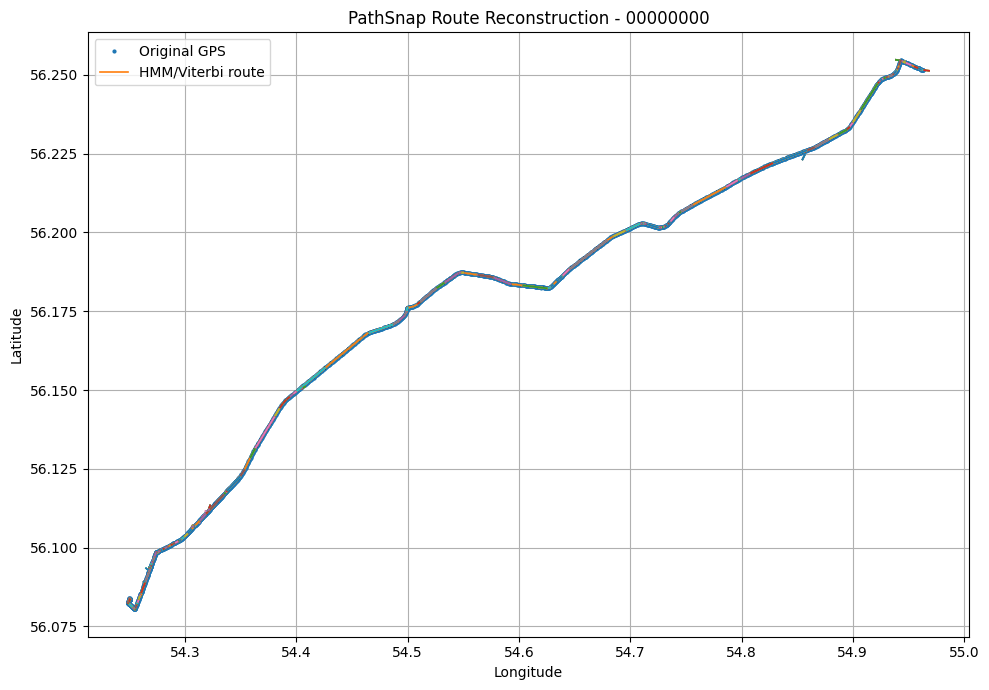

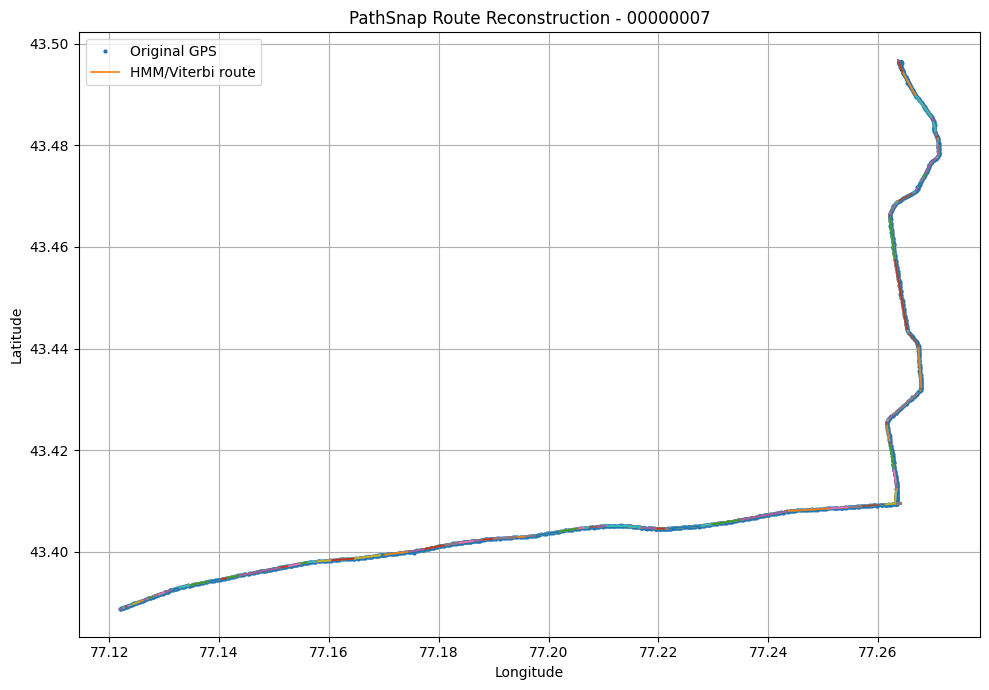

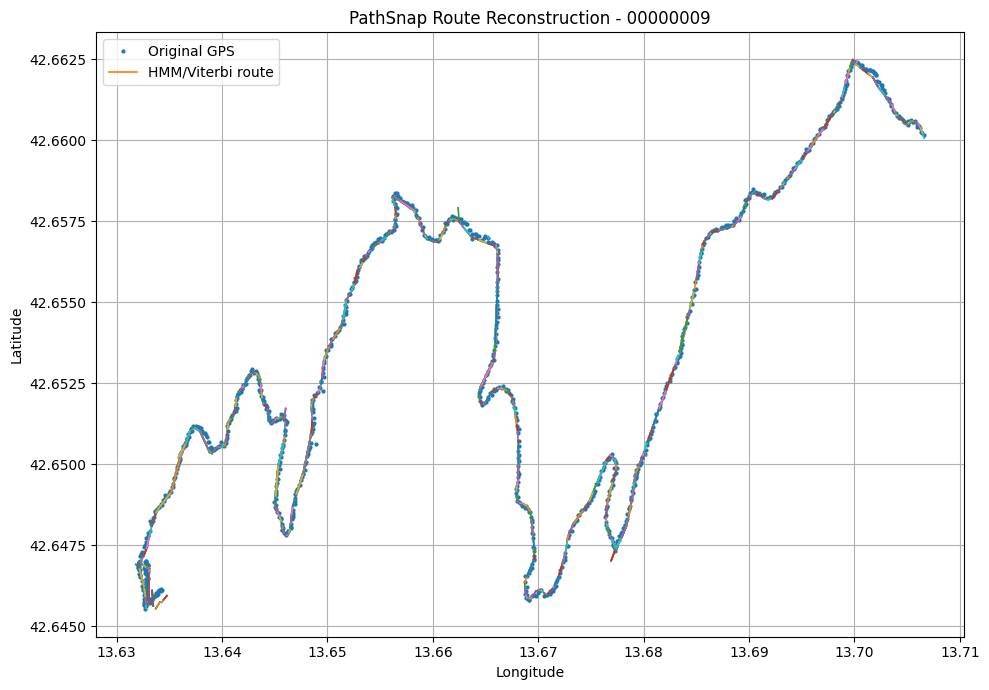

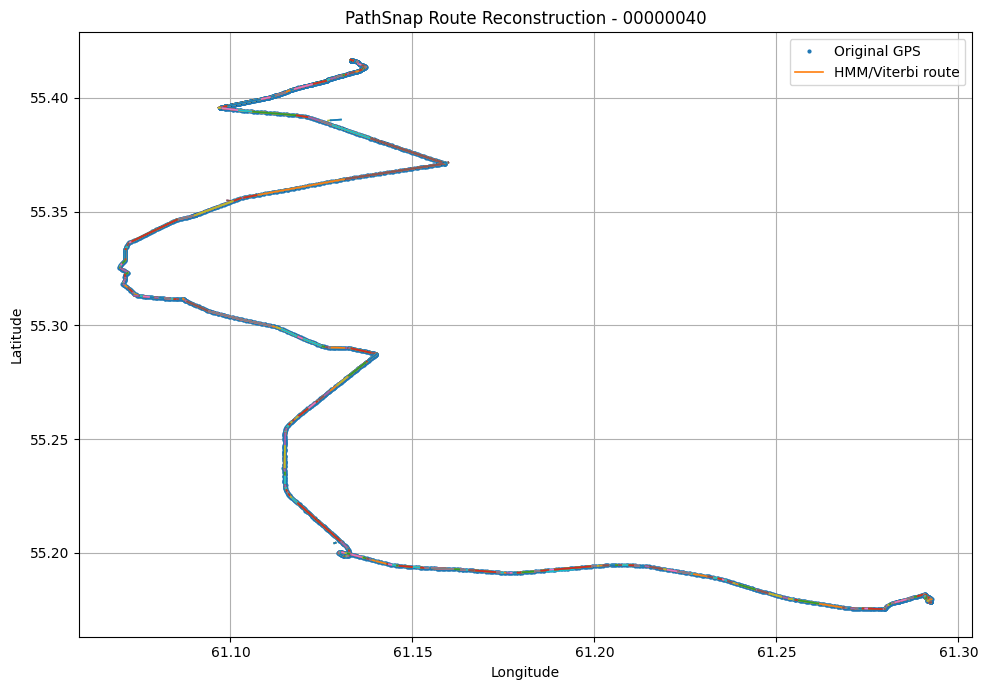

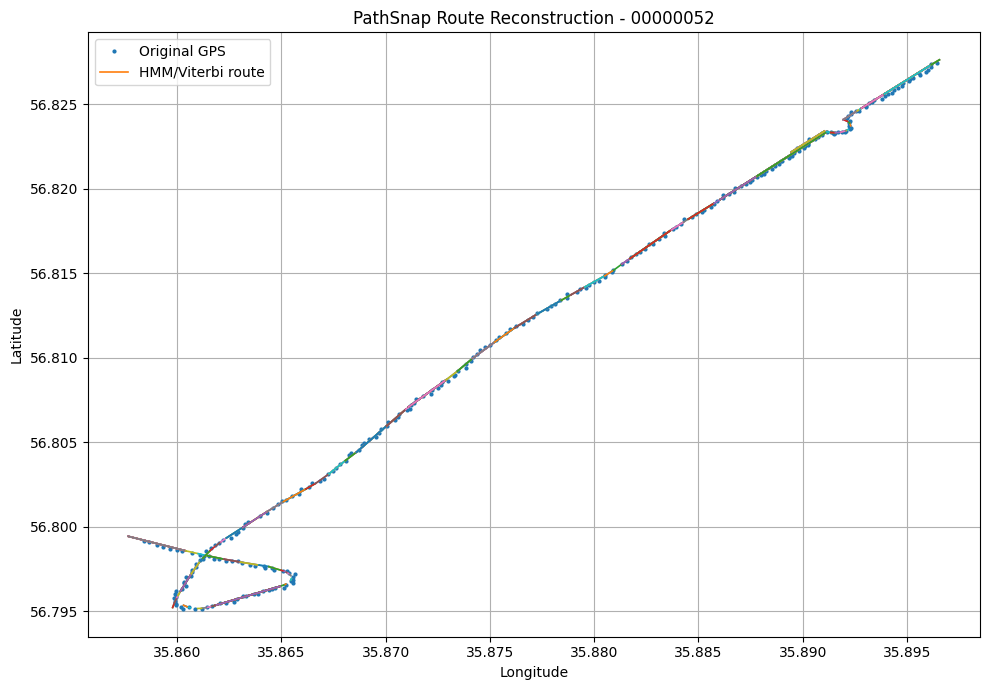

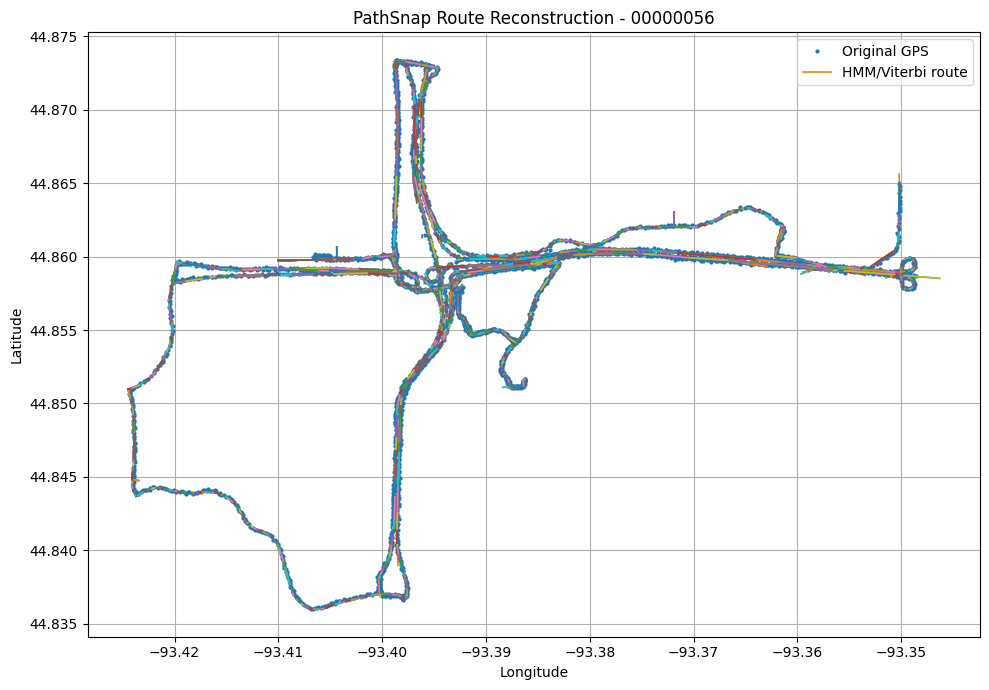

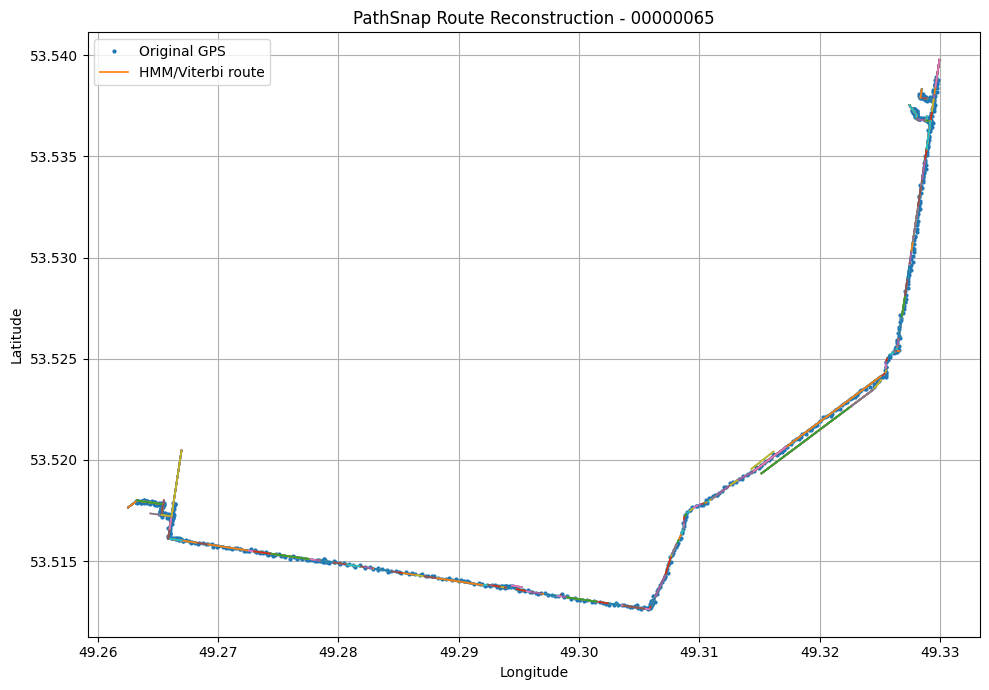

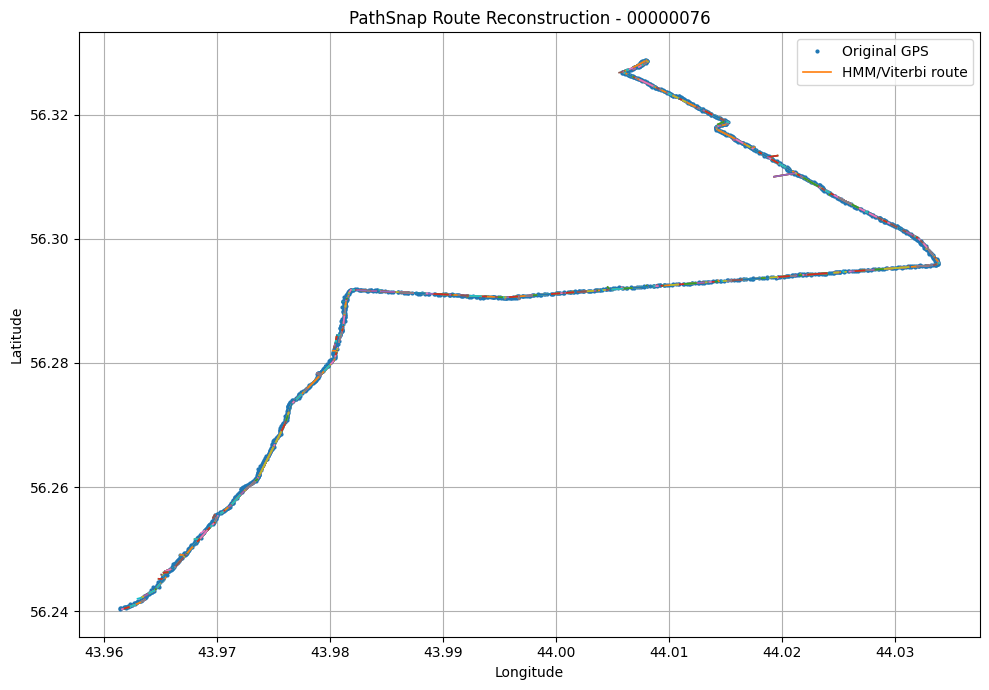

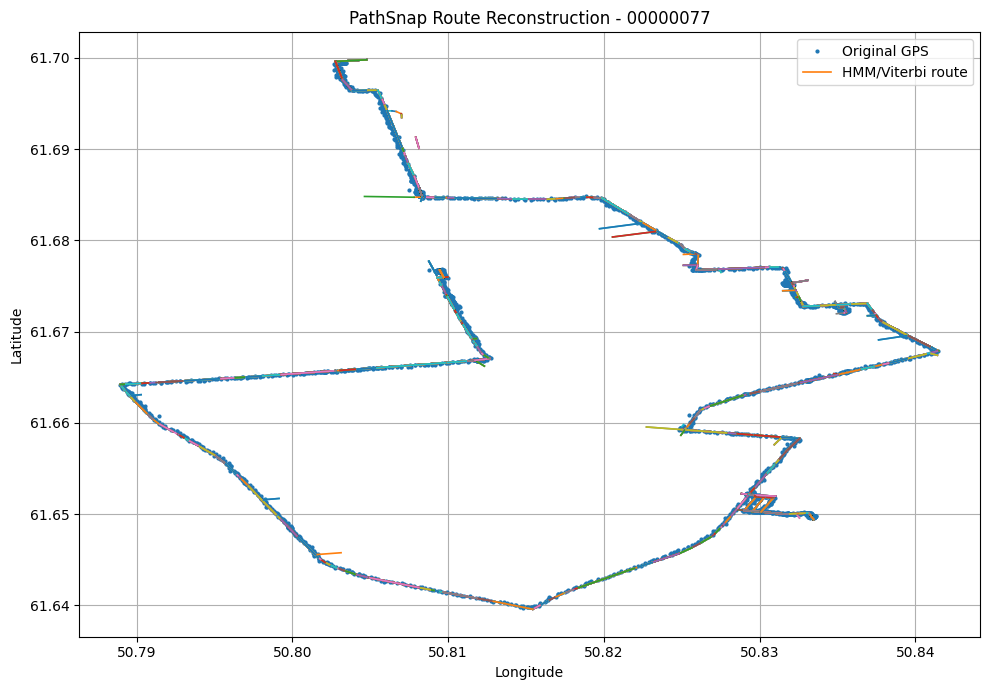

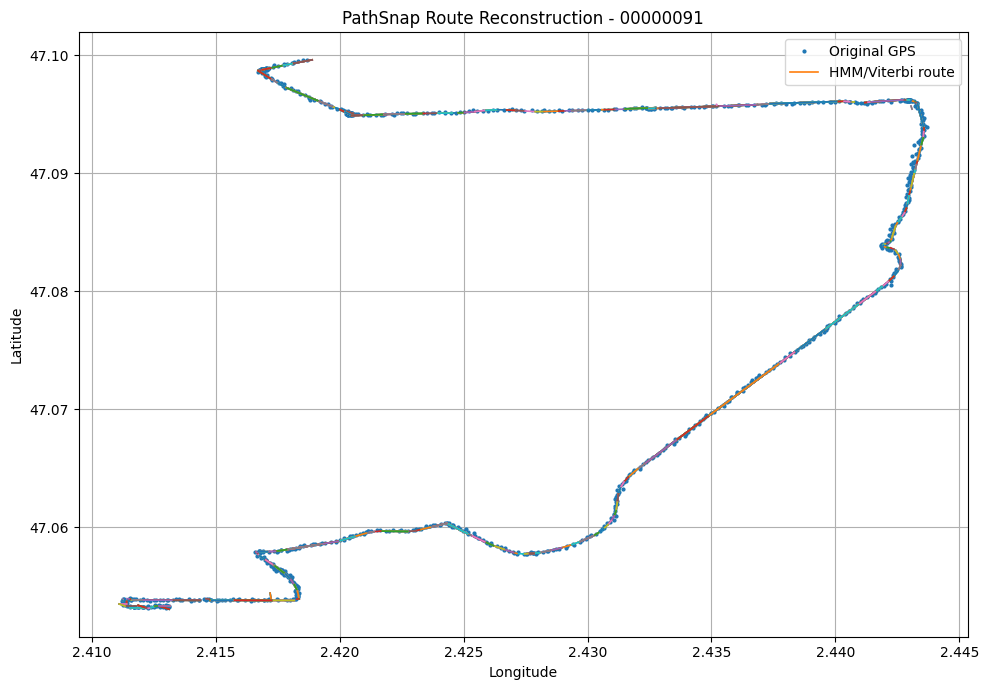


========== VISUALISATION SUMMARY ==========
Successful: 10
Failed: 0
Saved in: c:\Users\PAVAN KUMAR K M\OneDrive\Documents\Student folder\pathsnap_outputs


In [46]:
# ============================================================
# PATHSNAP: GPS vs HMM/VITERBI ROUTE VISUALISATION
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

hmm_path = OUTPUT_DIR / "tuned_rf_hmm_viterbi_test_predictions.csv"

hmm_predictions = pd.read_csv(hmm_path)

# Correct column names from your actual CSV
hmm_col = "hmm_predicted_arc_id"

hmm_predictions = hmm_predictions.dropna(
    subset=["trip_id", "gps_index", hmm_col]
).copy()

hmm_predictions["trip_id"] = (
    hmm_predictions["trip_id"].astype(str).str.zfill(8)
)

hmm_predictions["gps_index"] = (
    hmm_predictions["gps_index"].astype(int)
)

hmm_predictions[hmm_col] = (
    hmm_predictions[hmm_col].astype(int)
)

successful = 0
failed = []

for trip_id, group in hmm_predictions.groupby("trip_id"):

    try:
        folder = TEST_DIR / trip_id

        nodes = np.loadtxt(
            folder / f"{trip_id}.nodes",
            ndmin=2
        )

        arcs = np.loadtxt(
            folder / f"{trip_id}.arcs",
            dtype=int,
            ndmin=2
        )

        track = np.loadtxt(
            folder / f"{trip_id}.track",
            ndmin=2
        )

        group = group.sort_values("gps_index")

        arc_ids = group[hmm_col].to_numpy()

        # Validate arc IDs
        arc_ids = arc_ids[
            (arc_ids >= 0) & (arc_ids < len(arcs))
        ]

        plt.figure(figsize=(10, 7))

        plt.plot(
            track[:, 0],
            track[:, 1],
            "o",
            markersize=2,
            label="Original GPS"
        )

        first = True

        for arc_id in arc_ids:

            start, end = arcs[arc_id]

            if not (
                0 <= start < len(nodes)
                and 0 <= end < len(nodes)
            ):
                continue

            plt.plot(
                [nodes[start, 0], nodes[end, 0]],
                [nodes[start, 1], nodes[end, 1]],
                linewidth=1.2,
                label="HMM/Viterbi route" if first else None
            )

            first = False

        plt.title(f"PathSnap Route Reconstruction - {trip_id}")
        plt.xlabel("Longitude")
        plt.ylabel("Latitude")
        plt.legend()
        plt.grid(True)
        plt.tight_layout()

        plt.savefig(
            OUTPUT_DIR / f"route_visualisation_{trip_id}.png",
            dpi=200
        )

        plt.show()
        plt.close()

        successful += 1

    except Exception as e:
        failed.append({"trip_id": trip_id, "error": str(e)})
        print(f"{trip_id}: {e}")

print("\n========== VISUALISATION SUMMARY ==========")
print("Successful:", successful)
print("Failed:", len(failed))

if failed:
    display(pd.DataFrame(failed))

print("Saved in:", OUTPUT_DIR)

In [47]:
%pip install folium

  Using cached folium-1.0.0-py2.py3-none-any.whl.metadata (4.1 kB)
  Using cached branca-0.8.2-py3-none-any.whl.metadata (1.7 kB)
  Using cached xyzservices-2026.9.1-py3-none-any.whl.metadata (4.1 kB)
Using cached folium-1.0.0-py2.py3-none-any.whl (130 kB)
Using cached branca-0.8.2-py3-none-any.whl (26 kB)
Using cached xyzservices-2026.9.1-py3-none-any.whl (98 kB)

   ------------- -------------------------- 1/3 [branca]
   -------------------------- ------------- 2/3 [folium]
   -------------------------- ------------- 2/3 [folium]
   -------------------------- ------------- 2/3 [folium]
   -------------------------- ------------- 2/3 [folium]
   -------------------------- ------------- 2/3 [folium]
   -------------------------- ------------- 2/3 [folium]
   -------------------------- ------------- 2/3 [folium]
   ---------------------------------------- 3/3 [folium]

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [57]:

# ============================================================
# PATHSNAP - INTERACTIVE MAP VISUALISATION USING FOLIUM
# ============================================================

import folium
import pandas as pd
import numpy as np
from pathlib import Path

# Load HMM + Viterbi predictions
hmm_path = OUTPUT_DIR / "tuned_rf_hmm_viterbi_test_predictions.csv"
hmm_predictions = pd.read_csv(hmm_path)

hmm_col = "hmm_predicted_arc_id"

# Clean data
hmm_predictions = hmm_predictions.dropna(
    subset=["trip_id", "gps_index", hmm_col]
).copy()

hmm_predictions["trip_id"] = (
    hmm_predictions["trip_id"].astype(str).str.zfill(8)
)
hmm_predictions["gps_index"] = hmm_predictions["gps_index"].astype(int)
hmm_predictions[hmm_col] = hmm_predictions[hmm_col].astype(int)

# Output directory
FOLIUM_DIR = OUTPUT_DIR / "folium_maps"
FOLIUM_DIR.mkdir(parents=True, exist_ok=True)

successful = 0
failed = []

for trip_id, group in hmm_predictions.groupby("trip_id"):

    try:
        folder = Path(TEST_DIR) / trip_id

        nodes = np.loadtxt(
            folder / f"{trip_id}.nodes", ndmin=2
        )

        arcs = np.loadtxt(
            folder / f"{trip_id}.arcs",
            dtype=int, ndmin=2
        )

        track = np.loadtxt(
            folder / f"{trip_id}.track", ndmin=2
        )

        group = group.sort_values("gps_index")

        # GPS coordinates: longitude, latitude
        gps_coordinates = [
            (float(lat), float(lon))
            for lon, lat in track[:, :2]
            if np.isfinite(lon) and np.isfinite(lat)
        ]

        if not gps_coordinates:
            raise ValueError("No valid GPS coordinates")

        center_lat = np.mean([p[0] for p in gps_coordinates])
        center_lon = np.mean([p[1] for p in gps_coordinates])

        # CHANGED: Use CartoDB instead of OpenStreetMap
        fmap = folium.Map(
            location=[center_lat, center_lon],
            zoom_start=14,
            tiles=None
        )

        folium.TileLayer(
            tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}",
            attr="Tiles © Esri",
            name="Esri World Street Map",
            overlay=False,
            control=True
        ).add_to(fmap)

        # Original GPS trajectory
        gps_layer = folium.FeatureGroup(
            name="Original GPS Trajectory",
            show=True
        )

        folium.PolyLine(
            gps_coordinates,
            color="blue",
            weight=3,
            opacity=0.8,
            tooltip="Original GPS trajectory"
        ).add_to(gps_layer)

        folium.Marker(
            gps_coordinates[0],
            tooltip="GPS Start",
            icon=folium.Icon(color="green", icon="play")
        ).add_to(gps_layer)

        folium.Marker(
            gps_coordinates[-1],
            tooltip="GPS End",
            icon=folium.Icon(color="red", icon="stop")
        ).add_to(gps_layer)

        gps_layer.add_to(fmap)

        # HMM + Viterbi reconstructed route
        route_layer = folium.FeatureGroup(
            name="HMM + Viterbi Reconstructed Route",
            show=True
        )

        predicted_arc_ids = group[hmm_col].to_numpy()
        valid_count = 0

        for arc_id in predicted_arc_ids:

            if not (0 <= arc_id < len(arcs)):
                continue

            start_node, end_node = arcs[arc_id]

            if not (
                0 <= start_node < len(nodes)
                and 0 <= end_node < len(nodes)
            ):
                continue

            start_lon, start_lat = nodes[start_node, :2]
            end_lon, end_lat = nodes[end_node, :2]

            if not np.all(np.isfinite([
                start_lon, start_lat, end_lon, end_lat
            ])):
                continue

            folium.PolyLine(
                locations=[
                    (float(start_lat), float(start_lon)),
                    (float(end_lat), float(end_lon))
                ],
                color="red",
                weight=4,
                opacity=0.85
            ).add_to(route_layer)

            valid_count += 1

        route_layer.add_to(fmap)

        folium.LayerControl(collapsed=False).add_to(fmap)
        fmap.fit_bounds(gps_coordinates)

        output_file = FOLIUM_DIR / f"PathSnap_{trip_id}.html"
        fmap.save(str(output_file))

        successful += 1

        print(
            f"{trip_id}: Map saved | "
            f"GPS points: {len(gps_coordinates)} | "
            f"Road segments: {valid_count}"
        )

    except Exception as e:
        failed.append({"trip_id": trip_id, "error": str(e)})
        print(f"{trip_id}: FAILED - {e}")

print("\n========== FOLIUM VISUALISATION SUMMARY ==========")
print("Successful maps:", successful)
print("Failed maps:", len(failed))
print("Saved folder:", FOLIUM_DIR)

if failed:
    display(pd.DataFrame(failed))


00000000: Map saved | GPS points: 2503 | Road segments: 2503
00000007: Map saved | GPS points: 1354 | Road segments: 1354
00000009: Map saved | GPS points: 1049 | Road segments: 1049
00000040: Map saved | GPS points: 2995 | Road segments: 2995
00000052: Map saved | GPS points: 262 | Road segments: 262
00000056: Map saved | GPS points: 3958 | Road segments: 3958
00000065: Map saved | GPS points: 768 | Road segments: 768
00000076: Map saved | GPS points: 1486 | Road segments: 1486
00000077: Map saved | GPS points: 3911 | Road segments: 3911
00000091: Map saved | GPS points: 874 | Road segments: 874

========== FOLIUM VISUALISATION SUMMARY ==========
Successful maps: 10
Failed maps: 0
Saved folder: c:\Users\PAVAN KUMAR K M\OneDrive\Documents\Student folder\pathsnap_outputs\folium_maps


In [58]:

# Open the first generated Folium map in default browser

import webbrowser

map_files = sorted(FOLIUM_DIR.glob("PathSnap_*.html"))

if map_files:
    map_path = map_files[0].resolve()

    print("Opening:", map_path)
    webbrowser.open(map_path.as_uri())
else:
    print("No Folium maps found.")


Opening: C:\Users\PAVAN KUMAR K M\OneDrive\Documents\Student folder\pathsnap_outputs\folium_maps\PathSnap_00000000.html


In [50]:
# ============================================================
# FINAL HMM + VITERBI EVALUATION
# ============================================================

hmm_path = OUTPUT_DIR / "tuned_rf_hmm_viterbi_test_predictions.csv"

hmm_predictions = pd.read_csv(
    hmm_path,
    dtype={"trip_id": str}
)

hmm_predictions["trip_id"] = (
    hmm_predictions["trip_id"].str.zfill(8)
)

hmm_result = evaluate_predictions(
    "Tuned RF + HMM/Viterbi",
    hmm_predictions,
    "hmm_predicted_arc_id"
)

if hmm_result:
    print("\nHMM evaluation completed:")
    display(pd.DataFrame([hmm_result]))


Tuned RF + HMM/Viterbi
Confusion matrix:
[[5 0 0 ... 0 0 0]
 [0 2 0 ... 0 0 0]
 [0 0 9 ... 0 0 0]
 ...
 [0 0 0 ... 8 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 4]]

HMM evaluation completed:


,Model,Evaluated observations,Accuracy,Precision,Recall,F1-score
0,Tuned RF + HMM/Viterbi,10941,0.864729,0.736361,0.721344,0.717091


In [63]:

# ============================================================
# PATHSNAP - FINAL PROJECT SUMMARY
# ============================================================

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("=" * 55)
print("          PATHSNAP FINAL RESULTS")
print("=" * 55)

print("\n1. FIVE ML CLASSIFIERS")
models = [
    "KNN",
    "Random Forest",
    "LightGBM",
    "XGBoost",
    "Logistic Regression"
]

for model in models:
    print("-", model)

print("\n2. BAYESIAN OPTIMISATION")
print("Trials completed: 20")
print("Best CV Top-1 accuracy: 84.51%")
print("Best parameters:")
print({
    "n_estimators": 200,
    "max_depth": 13,
    "min_samples_split": 6,
    "min_samples_leaf": 5,
    "max_features": "sqrt"
})

print("\n3. STUDENT-TEST EVALUATION")

labels = pd.read_csv(
    OUTPUT_DIR / "student_test_virtual_labels.csv",
    dtype={"trip_id": str}
)

predictions = pd.read_csv(
    OUTPUT_DIR / "tuned_rf_hmm_viterbi_test_predictions.csv",
    dtype={"trip_id": str}
)

labels["trip_id"] = labels["trip_id"].str.zfill(8)
predictions["trip_id"] = predictions["trip_id"].str.zfill(8)

evaluation = labels[
    ["trip_id", "gps_index", "arc_id"]
].merge(
    predictions[
        ["trip_id", "gps_index", "hmm_predicted_arc_id"]
    ],
    on=["trip_id", "gps_index"],
    how="inner"
)

y_true = evaluation["arc_id"]
y_pred = evaluation["hmm_predicted_arc_id"]

print("Test trips:", evaluation["trip_id"].nunique())
print("Evaluated observations:", len(evaluation))
print("HMM + Viterbi accuracy:",
      round(accuracy_score(y_true, y_pred), 4))
print("Macro precision:",
      round(precision_score(y_true, y_pred,
                            average="macro", zero_division=0), 4))
print("Macro recall:",
      round(recall_score(y_true, y_pred,
                         average="macro", zero_division=0), 4))
print("Macro F1:",
      round(f1_score(y_true, y_pred,
                     average="macro", zero_division=0), 4))

print("\n4. ROUTE RECONSTRUCTION")
print("HMM + Viterbi predictions:", len(predictions))
print("Corrected route continuity:", round(hmm_continuity, 4))

print("\n5. FOLIUM VISUALISATION")
folium_files = list(
    (OUTPUT_DIR / "folium_maps").glob("PathSnap_*.html")
)
print("Interactive maps generated:", len(folium_files))

print("\n6. OUTPUT DIRECTORY")
print(OUTPUT_DIR)

print("\nPATHSNAP FINAL SUMMARY COMPLETED")
print("=" * 55)


          PATHSNAP FINAL RESULTS

1. FIVE ML CLASSIFIERS
- KNN
- Random Forest
- LightGBM
- XGBoost
- Logistic Regression

2. BAYESIAN OPTIMISATION
Trials completed: 20
Best CV Top-1 accuracy: 84.51%
Best parameters:
{'n_estimators': 200, 'max_depth': 13, 'min_samples_split': 6, 'min_samples_leaf': 5, 'max_features': 'sqrt'}

3. STUDENT-TEST EVALUATION
Test trips: 10
Evaluated observations: 10941
HMM + Viterbi accuracy: 0.8647
Macro precision: 0.7364
Macro recall: 0.7213
Macro F1: 0.7171

4. ROUTE RECONSTRUCTION
HMM + Viterbi predictions: 19160
Corrected route continuity: 0.9877

5. FOLIUM VISUALISATION
Interactive maps generated: 10

6. OUTPUT DIRECTORY
c:\Users\PAVAN KUMAR K M\OneDrive\Documents\Student folder\pathsnap_outputs

PATHSNAP FINAL SUMMARY COMPLETED
